In [1]:
import pandas as pd # to load the dataset

# analysis module
import matplotlib.pyplot as plt # to analysis the data
import seaborn as sns # to analysis the data

# to split the dataset, load the models, traning and testing

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, f1_score, recall_score, precision_score
from sklearn.decomposition import PCA 
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
import numpy as np
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import RandomForestClassifier 
from xgboost import XGBClassifier
from sklearn.ensemble import ExtraTreesClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay


from scipy.fftpack import fft
from scipy.signal import find_peaks, welch
import pywt
#from statsmodels.tsa.ar_model import AutoReg

# to ignore unnecessary warnings
import warnings 
warnings.filterwarnings('ignore')
import os
import glob

In [2]:
flicker_df = pd.read_csv("XPQRS/Flicker.csv")#done
flicker_with_sag_df = pd.read_csv("XPQRS/Flicker_with_Sag.csv")#done
flicker_with_swell_df = pd.read_csv("XPQRS/Flicker_with_Swell.csv")#done
harmonics_df = pd.read_csv("XPQRS/Harmonics.csv")#done
harmonics_with_sag_df = pd.read_csv("XPQRS/Harmonics_with_Sag.csv")#done
harmonics_with_swell_df = pd.read_csv("XPQRS/Harmonics_with_Swell.csv")#done
interruption_df = pd.read_csv("XPQRS/Interruption.csv")#done
notch_df = pd.read_csv("XPQRS/Notch.csv")#done
oscillatory_transient_df = pd.read_csv("XPQRS/Oscillatory_Transient.csv")#done
pure_sinusoidal_df = pd.read_csv("XPQRS/Pure_Sinusoidal.csv")#done
sag_df = pd.read_csv("XPQRS/Sag.csv")#done
sag_with_harmonics_df = pd.read_csv("XPQRS/Sag_with_Harmonics.csv")
sag_with_oscillatory_transient_df = pd.read_csv("XPQRS/Sag_with_Oscillatory_Transient.csv")#done
swell_df = pd.read_csv("XPQRS/Swell.csv")#done
swell_with_harmonics_df = pd.read_csv("XPQRS/Swell_with_Harmonics.csv")
swell_with_oscillatory_transient_df = pd.read_csv("XPQRS/Swell_with_Oscillatory_Transient.csv")#done
transient_df = pd.read_csv("XPQRS/Transient.csv")#done

In [3]:
flicker_df.head()

,0.998803016326019,1.00093035393725,0.999105553138814,0.993327593431853,0.983611102360254,0.969986334141963,0.952499086219062,0.931210553880993,0.906197123362766,0.877550104066715,...,0.839519074523991,0.880687604855291,0.918410664527645,0.952534833742929,0.982920921603107,1.00944454022342,1.03199661970499,1.05048386180353,1.0648291303785,1.07497177696332
0,0.626540,0.576782,0.524674,0.470417,0.414224,0.356313,0.296911,0.236251,0.174570,0.112111,...,1.015561,0.996524,0.973534,0.946680,0.916066,0.881813,0.844053,0.802935,0.758621,0.711284
1,0.088343,0.025671,-0.037334,-0.100424,-0.163349,-0.225856,-0.287697,-0.348623,-0.408388,-0.466749,...,0.720869,0.667349,0.611201,0.552653,0.491943,0.429319,0.365034,0.299349,0.232530,0.164849
2,0.067605,0.130368,0.192856,0.254818,0.316005,0.376170,0.435068,0.492458,0.548104,0.601776,...,-0.542400,-0.486215,-0.428306,-0.368910,-0.308271,-0.246637,-0.184257,-0.121383,-0.058267,0.004839
3,0.968689,0.953218,0.933902,0.910800,0.883986,0.853551,0.819599,0.782252,0.741643,0.697919,...,1.002791,1.024722,1.042525,1.056137,1.065512,1.070622,1.071457,1.068024,1.060349,1.048474
4,0.952476,0.970862,0.985453,0.996180,1.002994,1.005857,1.004748,0.999663,0.990612,0.977622,...,0.639812,0.693569,0.744618,0.792753,0.837779,0.879515,0.917793,0.952457,0.983368,1.010399


In [4]:
harmonics_df.head()

,-0.118791500597708,-0.0330210561312059,0.0453727222087239,0.118880097999327,0.189827979991755,0.259670491326418,0.328563907503245,0.395309361960064,0.457665688412558,0.512954386122759,...,-0.965762576704286,-0.956670984603969,-0.918905250771148,-0.853763028997658,-0.765551341518573,-0.660702560016634,-0.546623048809677,-0.430490943035578,-0.318217742208638,-0.213747029666977
0,-0.865092,-0.884290,-0.910850,-0.944373,-0.982522,-1.021550,-1.057052,-1.084784,-1.101398,-1.104960,...,-0.325717,-0.439215,-0.544652,-0.636085,-0.709740,-0.764458,-0.801703,-0.825142,-0.839887,-0.851517
1,-0.469072,-0.520378,-0.547554,-0.552598,-0.540502,-0.518550,-0.495253,-0.479090,-0.477261,-0.494665,...,0.372057,0.328879,0.273895,0.204274,0.119345,0.020977,-0.086463,-0.196599,-0.301911,-0.394861
2,0.558254,0.488038,0.390984,0.276215,0.155178,0.039521,-0.061007,-0.140245,-0.196603,-0.233145,...,0.589997,0.516901,0.471913,0.457519,0.470831,0.504039,0.545729,0.582860,0.603021,0.596570
3,1.266193,1.276133,1.248968,1.193697,1.122143,1.046834,0.978880,0.926216,0.892529,0.877012,...,0.232490,0.259006,0.320035,0.416696,0.544288,0.692893,0.848867,0.996961,1.122714,1.214692
4,0.595707,0.555276,0.492447,0.410535,0.315070,0.212770,0.110412,0.013785,-0.073080,-0.148312,...,0.715067,0.639192,0.583845,0.551847,0.542415,0.551313,0.571536,0.594426,0.611007,0.613349


In [5]:
harmonics_df.shape

(999, 100)

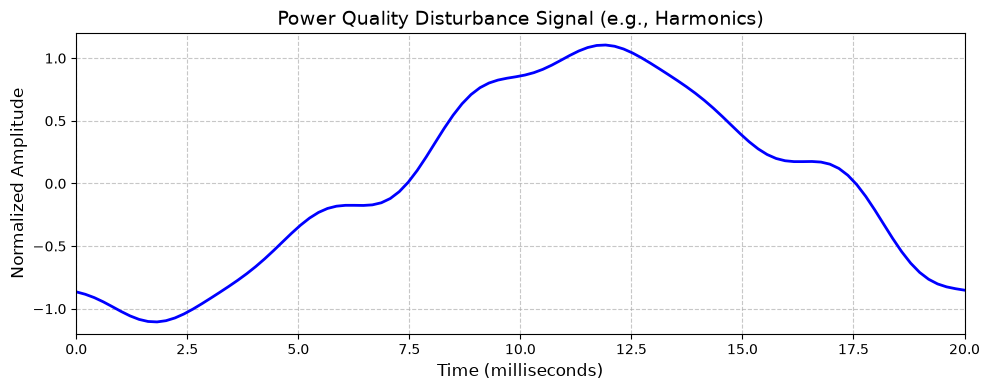

In [6]:

# 1. Load one of the dataset files (e.g., 'Sag.csv')
# Make sure the CSV file is in the same directory as your notebook
df = harmonics_df

# 2. Select a single row to visualize (e.g., row index 0)
signal_row = df.iloc[0].values

# 3. Create a time axis
# 100 samples representing 20 milliseconds
time_axis = np.linspace(0, 20, num=100)

# 4. Plot the wave using Matplotlib
plt.figure(figsize=(10, 4))
plt.plot(time_axis, signal_row, color='b', linewidth=2)

# 5. Format the plot
plt.title("Power Quality Disturbance Signal (e.g., Harmonics)", fontsize=14)
plt.xlabel("Time (milliseconds)", fontsize=12)
plt.ylabel("Normalized Amplitude", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Ensure the y-axis shows the full -1 to 1 normalized range (plus a little padding)
plt.ylim(-1.2, 1.2)
plt.xlim(0, 20)

plt.tight_layout()
plt.show()

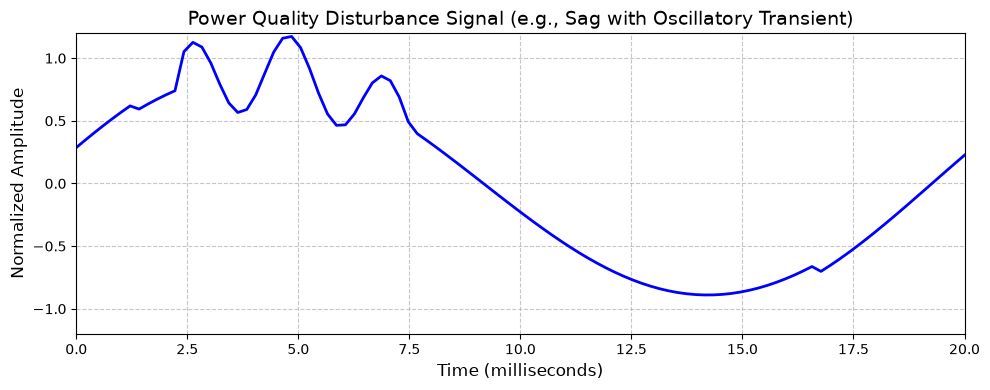

In [7]:

# 1. Load one of the dataset files (e.g., 'Sag.csv')
# Make sure the CSV file is in the same directory as your notebook
df = sag_with_oscillatory_transient_df

# 2. Select a single row to visualize (e.g., row index 0)
signal_row = df.iloc[0].values

# 3. Create a time axis
# 100 samples representing 20 milliseconds
time_axis = np.linspace(0, 20, num=100)

# 4. Plot the wave using Matplotlib
plt.figure(figsize=(10, 4))
plt.plot(time_axis, signal_row, color='b', linewidth=2)

# 5. Format the plot
plt.title("Power Quality Disturbance Signal (e.g., Sag with Oscillatory Transient)", fontsize=14)
plt.xlabel("Time (milliseconds)", fontsize=12)
plt.ylabel("Normalized Amplitude", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Ensure the y-axis shows the full -1 to 1 normalized range (plus a little padding)
plt.ylim(-1.2, 1.2)
plt.xlim(0, 20)

plt.tight_layout()
plt.show()

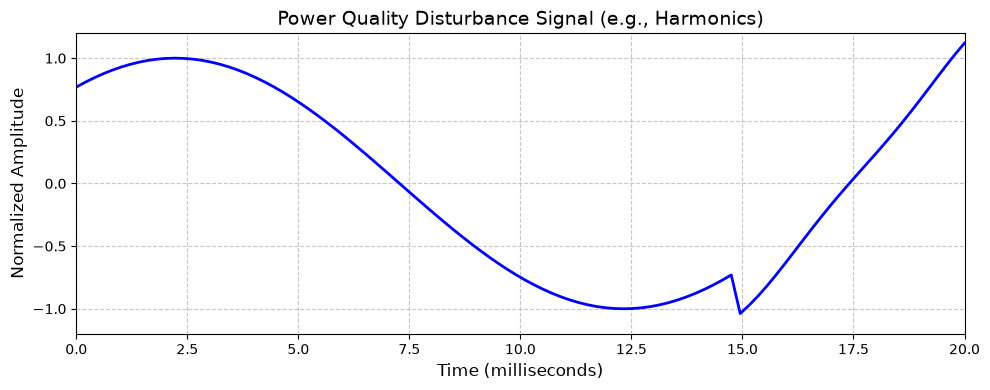

In [8]:

# 1. Load one of the dataset files (e.g., 'Sag.csv')
# Make sure the CSV file is in the same directory as your notebook
df = swell_with_harmonics_df

# 2. Select a single row to visualize (e.g., row index 0)
signal_row = df.iloc[2].values

# 3. Create a time axis
# 100 samples representing 20 milliseconds
time_axis = np.linspace(0, 20, num=100)

# 4. Plot the wave using Matplotlib
plt.figure(figsize=(10, 4))
plt.plot(time_axis, signal_row, color='b', linewidth=2)

# 5. Format the plot
plt.title("Power Quality Disturbance Signal (e.g., Harmonics)", fontsize=14)
plt.xlabel("Time (milliseconds)", fontsize=12)
plt.ylabel("Normalized Amplitude", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# Ensure the y-axis shows the full -1 to 1 normalized range (plus a little padding)
plt.ylim(-1.2, 1.2)
plt.xlim(0, 20)

plt.tight_layout()
plt.show()

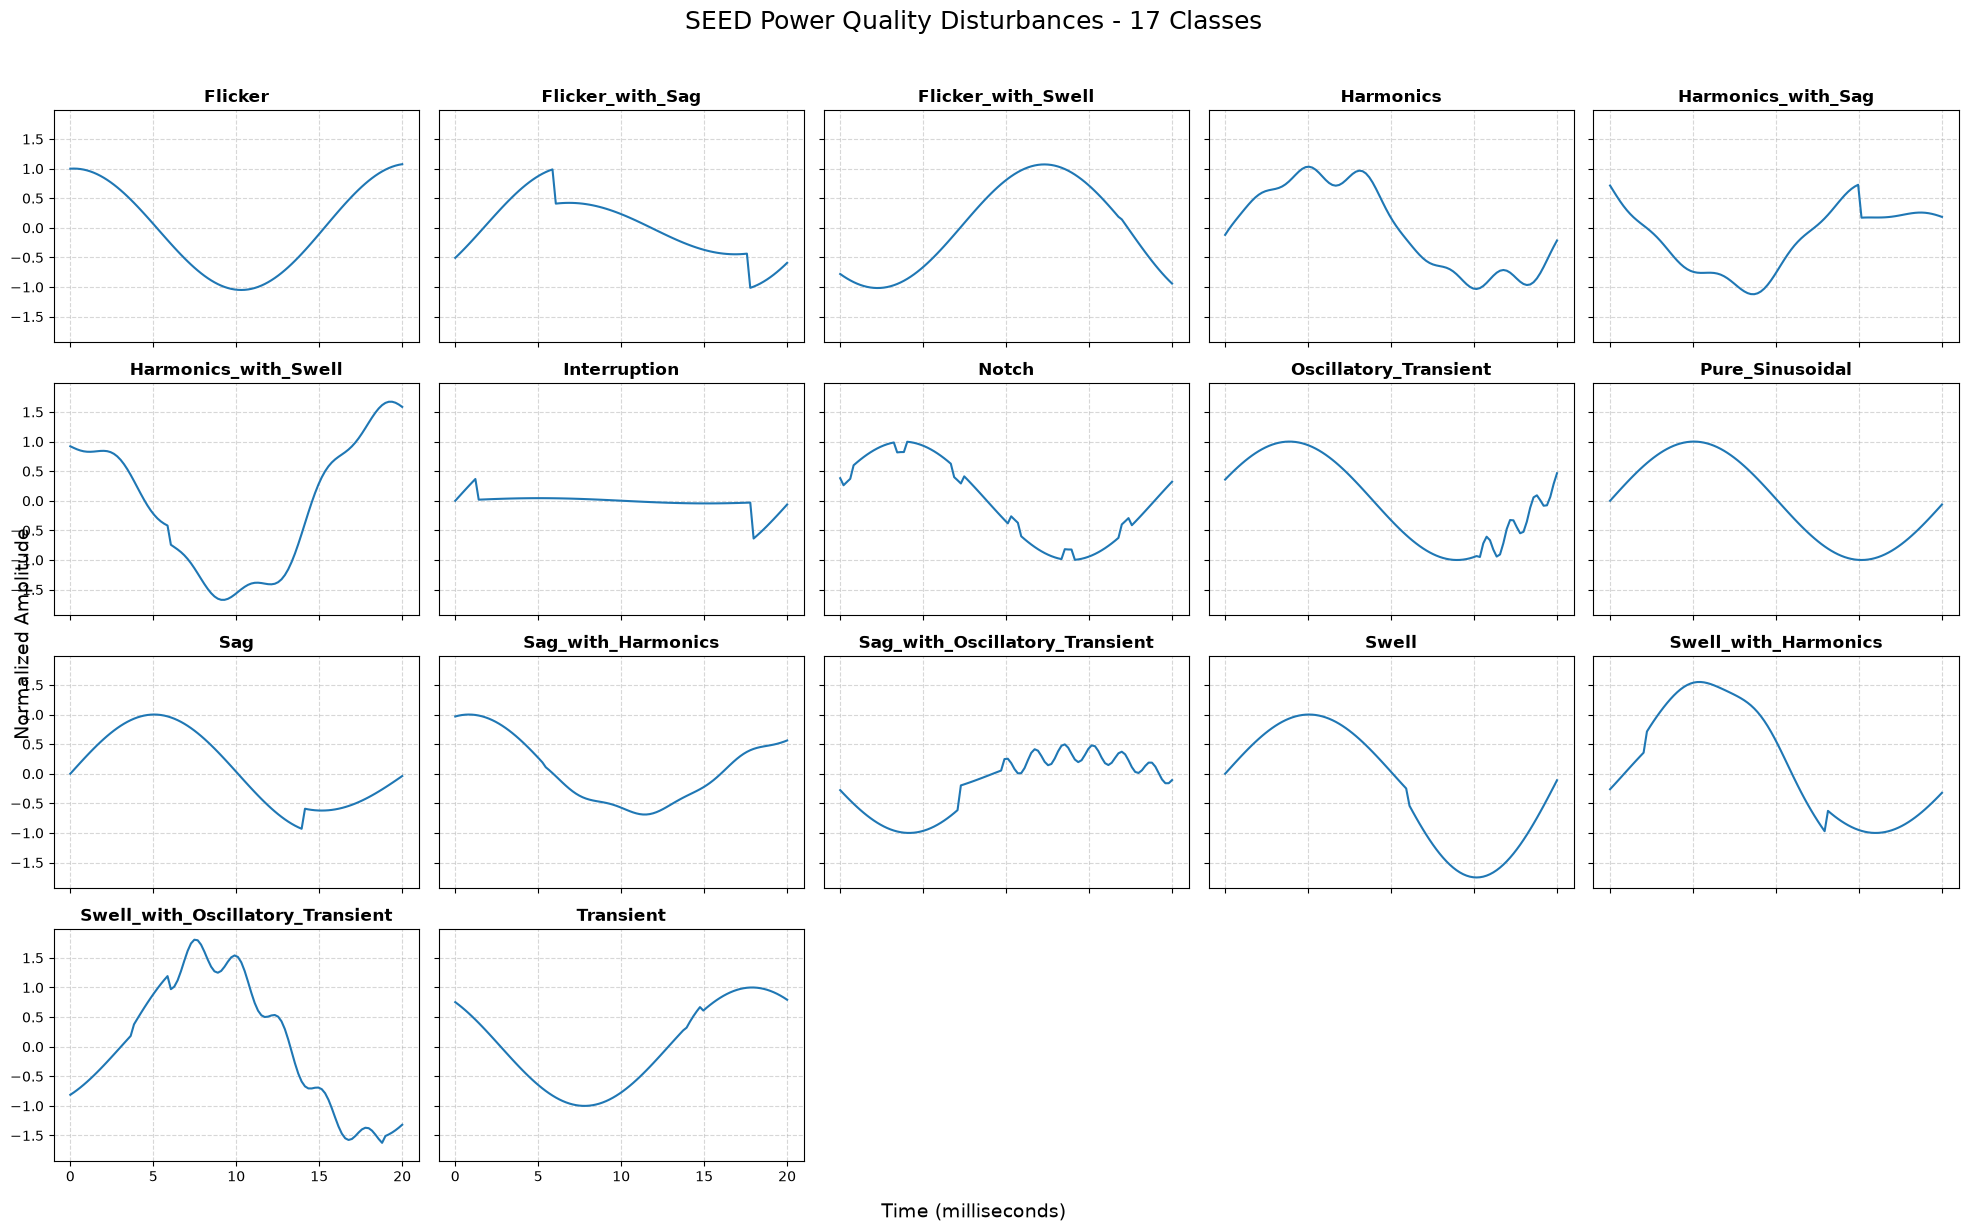

In [9]:

csv_files = glob.glob('XPQRS/*.csv')
fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(20, 12), sharex=True, sharey=True)

# Flatten the 2D axes array into a 1D list so we can loop through it easily
axes = axes.flatten()

# 100 samples representing 20 milliseconds
time_axis = np.linspace(0, 20, num=100)

# 3. Loop through each file and plot its first row
for i, file in enumerate(csv_files):
    if i >= 17:  # Stop if there are extra CSVs in the folder
        break
        
    # Extract the class name from the filename (e.g., 'Sag.csv' -> 'Sag')
    class_name = os.path.splitext(os.path.basename(file))[0]
    
    # Read ONLY the first row to save memory and time
    df = pd.read_csv(file, header=None, nrows=1)
    signal_row = df.iloc[0].values
    
    # Plot on the specific subplot grid item
    ax = axes[i]
    ax.plot(time_axis, signal_row, color='#1f77b4', linewidth=1.5)
    
    # Format the individual subplot
    ax.set_title(class_name, fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.5)

# 4. Remove the empty subplots (indices 17, 18, and 19)
for j in range(len(csv_files), len(axes)):
    fig.delaxes(axes[j])

# 5. Add global labels and adjust layout
fig.supxlabel('Time (milliseconds)', fontsize=14)
fig.supylabel('Normalized Amplitude', fontsize=14)
fig.suptitle('SEED Power Quality Disturbances - 17 Classes', fontsize=18, y=1.02)

plt.tight_layout()
plt.show()

In [10]:
def rename_columns(df):
    # Example: Rename columns as 'Column_1', 'Column_2', etc.
    new_column_names = [f"Column_{i+1}" for i in range(len(df.columns))]
    df.columns = new_column_names
    return df

In [11]:
flicker_df = rename_columns(flicker_df)
flicker_with_sag_df = rename_columns(flicker_with_sag_df)
flicker_with_swell_df = rename_columns(flicker_with_swell_df)
harmonics_df = rename_columns(harmonics_df)
harmonics_with_sag_df = rename_columns(harmonics_with_sag_df)
harmonics_with_swell_df = rename_columns(harmonics_with_swell_df)
interruption_df = rename_columns(interruption_df)
notch_df = rename_columns(notch_df)
oscillatory_transient_df = rename_columns(oscillatory_transient_df)
pure_sinusoidal_df = rename_columns(pure_sinusoidal_df)
sag_df = rename_columns(sag_df)
sag_with_harmonics_df = rename_columns(sag_with_harmonics_df)
sag_with_oscillatory_transient_df = rename_columns(sag_with_oscillatory_transient_df)
swell_df = rename_columns(swell_df)
swell_with_harmonics_df = rename_columns(swell_with_harmonics_df)
swell_with_oscillatory_transient_df = rename_columns(swell_with_oscillatory_transient_df)
transient_df = rename_columns(transient_df)

In [12]:
flicker_df.head()

,Column_1,Column_2,Column_3,Column_4,Column_5,Column_6,Column_7,Column_8,Column_9,Column_10,...,Column_91,Column_92,Column_93,Column_94,Column_95,Column_96,Column_97,Column_98,Column_99,Column_100
0,0.626540,0.576782,0.524674,0.470417,0.414224,0.356313,0.296911,0.236251,0.174570,0.112111,...,1.015561,0.996524,0.973534,0.946680,0.916066,0.881813,0.844053,0.802935,0.758621,0.711284
1,0.088343,0.025671,-0.037334,-0.100424,-0.163349,-0.225856,-0.287697,-0.348623,-0.408388,-0.466749,...,0.720869,0.667349,0.611201,0.552653,0.491943,0.429319,0.365034,0.299349,0.232530,0.164849
2,0.067605,0.130368,0.192856,0.254818,0.316005,0.376170,0.435068,0.492458,0.548104,0.601776,...,-0.542400,-0.486215,-0.428306,-0.368910,-0.308271,-0.246637,-0.184257,-0.121383,-0.058267,0.004839
3,0.968689,0.953218,0.933902,0.910800,0.883986,0.853551,0.819599,0.782252,0.741643,0.697919,...,1.002791,1.024722,1.042525,1.056137,1.065512,1.070622,1.071457,1.068024,1.060349,1.048474
4,0.952476,0.970862,0.985453,0.996180,1.002994,1.005857,1.004748,0.999663,0.990612,0.977622,...,0.639812,0.693569,0.744618,0.792753,0.837779,0.879515,0.917793,0.952457,0.983368,1.010399


In [13]:
flicker_df['class'] = 'Flicker'
flicker_with_sag_df['class'] = 'Flicker with Sag'
flicker_with_swell_df['class'] = 'Flicker with Swell'
harmonics_df['class'] = 'Harmonics' 
harmonics_with_sag_df['class'] = 'Harmonics with Sag'
harmonics_with_swell_df['class'] = 'Harmonics with Swell'
interruption_df['class'] = 'Interruption'
notch_df['class'] = 'Notch'
oscillatory_transient_df['class'] = 'Oscillatory Transient'
pure_sinusoidal_df['class'] = 'Pure Sinusoidal'
sag_df['class'] = 'Sag'
sag_with_harmonics_df['class'] = 'Sag with Harmonics'
sag_with_oscillatory_transient_df['class'] = 'Sag with Oscillatory'
swell_df['class'] = 'Swell'
swell_with_harmonics_df['class'] = 'Swell with Harmonics'
swell_with_oscillatory_transient_df['class'] = 'Swell with Oscillatory Transient'
transient_df['class'] = 'Transient'

In [14]:
swell_df.head(1)

,Column_1,Column_2,Column_3,Column_4,Column_5,Column_6,Column_7,Column_8,Column_9,Column_10,...,Column_92,Column_93,Column_94,Column_95,Column_96,Column_97,Column_98,Column_99,Column_100,class
0,0,0.062791,0.125333,0.187381,0.24869,0.309017,0.368125,0.425779,0.481754,0.535827,...,-0.535827,-0.481754,-0.425779,-0.368125,-0.309017,-0.24869,-0.187381,-0.125333,-0.062791,Swell


In [15]:
combined_df = pd.concat([flicker_df, flicker_with_sag_df, flicker_with_swell_df, harmonics_df, harmonics_with_sag_df, harmonics_with_swell_df, interruption_df, notch_df, oscillatory_transient_df, pure_sinusoidal_df, sag_df, sag_with_harmonics_df,sag_with_oscillatory_transient_df, swell_df,swell_with_harmonics_df, swell_with_oscillatory_transient_df, transient_df], axis=0)
combined_df.shape

(16983, 101)

In [16]:
resample_df = combined_df.sample(frac=1,random_state=42).reset_index(drop=True)
resample_df.head()         
# resample_df.to_csv("PQD.csv")

,Column_1,Column_2,Column_3,Column_4,Column_5,Column_6,Column_7,Column_8,Column_9,Column_10,...,Column_92,Column_93,Column_94,Column_95,Column_96,Column_97,Column_98,Column_99,Column_100,class
0,0.095917,0.153063,0.212028,0.273147,0.336276,0.400790,0.465618,0.529341,0.590324,0.646883,...,-0.603413,-0.507081,-0.414284,-0.326173,-0.243196,-0.165131,-0.091179,-0.020116,0.049515,Harmonics with Swell
1,0.967636,0.983320,0.995166,1.003109,1.007103,1.007117,1.003136,0.995158,0.983202,0.967300,...,0.580890,0.617666,0.651846,0.683304,0.711927,0.737612,0.760270,0.936748,0.956769,Flicker with Sag
2,-0.937272,-0.957311,-0.973572,-0.985991,-0.994519,-0.999122,-0.999781,-0.996495,-0.989277,-0.978154,...,-0.899237,-0.987655,-1.073017,-1.153995,-1.229331,-1.297921,-1.358886,-1.411624,-1.455838,Swell with Harmonics
3,0.000000,0.062791,0.125333,0.187381,0.248690,0.309017,0.368125,0.425779,0.481754,0.535827,...,-0.046466,-0.041777,-0.036923,-0.031923,-0.026798,-0.021566,-0.016250,-0.010869,-0.005445,Interruption
4,-0.093190,-0.149109,-0.175381,-0.180893,-0.177200,-0.176275,-0.188286,-0.219817,-0.272843,-0.344641,...,0.960631,0.927557,0.851659,0.736532,0.591511,0.430117,0.267803,0.119401,-0.003265,Harmonics


In [17]:
pqd_data_cleaned = resample_df
# Select numerical features
numerical_features = pqd_data_cleaned.iloc[:, :-1]
numerical_features.head()

,Column_1,Column_2,Column_3,Column_4,Column_5,Column_6,Column_7,Column_8,Column_9,Column_10,...,Column_91,Column_92,Column_93,Column_94,Column_95,Column_96,Column_97,Column_98,Column_99,Column_100
0,0.095917,0.153063,0.212028,0.273147,0.336276,0.400790,0.465618,0.529341,0.590324,0.646883,...,-0.701472,-0.603413,-0.507081,-0.414284,-0.326173,-0.243196,-0.165131,-0.091179,-0.020116,0.049515
1,0.967636,0.983320,0.995166,1.003109,1.007103,1.007117,1.003136,0.995158,0.983202,0.967300,...,0.541655,0.580890,0.617666,0.651846,0.683304,0.711927,0.737612,0.760270,0.936748,0.956769
2,-0.937272,-0.957311,-0.973572,-0.985991,-0.994519,-0.999122,-0.999781,-0.996495,-0.989277,-0.978154,...,-0.809065,-0.899237,-0.987655,-1.073017,-1.153995,-1.229331,-1.297921,-1.358886,-1.411624,-1.455838
3,0.000000,0.062791,0.125333,0.187381,0.248690,0.309017,0.368125,0.425779,0.481754,0.535827,...,-0.050972,-0.046466,-0.041777,-0.036923,-0.031923,-0.026798,-0.021566,-0.016250,-0.010869,-0.005445
4,-0.093190,-0.149109,-0.175381,-0.180893,-0.177200,-0.176275,-0.188286,-0.219817,-0.272843,-0.344641,...,0.953603,0.960631,0.927557,0.851659,0.736532,0.591511,0.430117,0.267803,0.119401,-0.003265


In [18]:
from sklearn.preprocessing import LabelEncoder

le=LabelEncoder()
resample_df['class']=le.fit_transform(resample_df['class'])

label_mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print(label_mapping)

{'Flicker': np.int64(0), 'Flicker with Sag': np.int64(1), 'Flicker with Swell': np.int64(2), 'Harmonics': np.int64(3), 'Harmonics with Sag': np.int64(4), 'Harmonics with Swell': np.int64(5), 'Interruption': np.int64(6), 'Notch': np.int64(7), 'Oscillatory Transient': np.int64(8), 'Pure Sinusoidal': np.int64(9), 'Sag': np.int64(10), 'Sag with Harmonics': np.int64(11), 'Sag with Oscillatory': np.int64(12), 'Swell': np.int64(13), 'Swell with Harmonics': np.int64(14), 'Swell with Oscillatory Transient': np.int64(15), 'Transient': np.int64(16)}


In [19]:
from sklearn.preprocessing import StandardScaler
from scipy.fftpack import fft
sl=StandardScaler()
scaled_features=sl.fit_transform(numerical_features)
scaled_df=pd.DataFrame(scaled_features,columns=numerical_features.columns)

#td
stat_features = pd.DataFrame()
stat_features['mean'] = numerical_features.mean(axis=1)
stat_features['std_dev'] = numerical_features.std(axis=1)
stat_features['min'] = numerical_features.min(axis=1)
stat_features['max'] = numerical_features.max(axis=1)
stat_features['skewness'] = numerical_features.skew(axis=1)
stat_features['kurtosis'] = numerical_features.kurt(axis=1)
stat_features['median'] = numerical_features.median(axis=1)
stat_features['iqr'] = numerical_features.quantile(0.75, axis=1) - numerical_features.quantile(0.25, axis=1)
stat_features['range'] = stat_features['max'] - stat_features['min']
stat_features['energy'] = (numerical_features**2).sum(axis=1)
stat_features['rms'] = np.sqrt((numerical_features**2).mean(axis=1))
stat_features['variance'] = numerical_features.var(axis=1)
stat_features['entropy'] = -(numerical_features * np.log1p(numerical_features)).sum(axis=1)

#fd
fft_vals = np.abs(fft(numerical_features, axis=1))
stat_features['fft_mean'] = fft_vals.mean(axis=1)
stat_features['fft_std_dev'] = fft_vals.std(axis=1)
stat_features['fft_max'] = fft_vals.max(axis=1)
stat_features['fft_energy'] = (fft_vals**2).sum(axis=1)

# --- HARMONICS (Vectorized Addition) ---
half_n = numerical_features.shape[1] // 2
pos_fft = fft_vals[:, :half_n] # Isolate positive frequencies

# Locate fundamental frequency index per row (excluding DC at index 0)
fund_idx = np.argmax(pos_fft[:, 1:], axis=1) + 1
row_idx = np.arange(pos_fft.shape[0])
fund_amp = pos_fft[row_idx, fund_idx]

# Mask to prevent division by zero errors
fund_amp_safe = np.where(fund_amp == 0, 1, fund_amp)

# Extract 3rd, 5th, and 7th harmonics safely
for h, col_name in zip([3, 5, 7], ['h3_ratio', 'h5_ratio', 'h7_ratio']):
    target_idx = fund_idx * h
    valid_mask = target_idx < half_n
    h_amp = np.zeros_like(fund_amp)
    h_amp[valid_mask] = pos_fft[row_idx[valid_mask], target_idx[valid_mask]]
    stat_features[col_name] = np.where(fund_amp == 0, 0, h_amp / fund_amp_safe)

# Calculate Global THD (Total Energy - DC Energy - Fundamental Energy)
residual_energy = np.sum(pos_fft**2, axis=1) - (pos_fft[:, 0]**2) - (fund_amp**2)
residual_energy = np.clip(residual_energy, 0, None) # Floor at 0 to prevent float precision negatives
stat_features['thd_global'] = np.where(fund_amp == 0, 0, np.sqrt(residual_energy) / fund_amp_safe)
stat_features['fundamental_amp'] = fund_amp
#tfd
def extract_wavelet_features(data, wavelet='db4'):
    coeffs = pywt.wavedec(data, wavelet, level=5)
    return [np.mean(np.abs(c)) for c in coeffs]

wavelet_features = numerical_features.apply(extract_wavelet_features, axis=1, result_type="expand")
wavelet_features.columns = [f'wavelet_coef_{i}' for i in range(wavelet_features.shape[1])]
stat_features = pd.concat([stat_features, wavelet_features], axis=1)

#shapes
stat_features['crest_factor'] = stat_features['max'] / stat_features['rms']
stat_features['impulse_factor'] = stat_features['max'] / stat_features['mean']
stat_features['shape_factor'] = stat_features['rms'] / stat_features['mean']

In [20]:
stat_features.head()

,mean,std_dev,min,max,skewness,kurtosis,median,iqr,range,energy,...,fundamental_amp,wavelet_coef_0,wavelet_coef_1,wavelet_coef_2,wavelet_coef_3,wavelet_coef_4,wavelet_coef_5,crest_factor,impulse_factor,shape_factor
0,-7.034592e-02,0.798863,-1.253849,1.009019,-1.144105e-01,-1.542148,-1.963916e-03,1.747679,2.262868,63.674862,...,55.791688,2.170072,0.637564,0.324934,0.089455,0.017509,0.001549,1.264490,-1.434368e+01,-1.134345e+01
1,2.565453e-02,0.662251,-0.889270,1.007117,6.843548e-02,-1.468954,3.310847e-04,1.270120,1.896388,43.484932,...,46.522596,4.949774,0.390277,0.045844,0.025208,0.012235,0.004160,1.527252,3.925691e+01,2.570428e+01
2,-3.399867e-03,0.824652,-1.455838,1.394092,-2.087441e-02,-1.419480,-6.076184e-03,1.644720,2.849929,67.326142,...,56.814460,5.444369,0.704602,0.158398,0.058992,0.021950,0.004002,1.699024,-4.100430e+02,-2.413403e+02
3,2.344080e-01,0.406080,-0.086719,1.000000,9.798433e-01,-0.820780,5.310002e-18,0.660521,1.086719,21.819932,...,24.491876,1.041557,0.399090,0.111082,0.065394,0.018165,0.009776,2.140786,4.266065e+00,1.992756e+00
4,2.345259e-16,0.724023,-1.090403,1.090403,-6.723533e-16,-1.526276,8.298483e-16,1.492574,2.180805,51.896656,...,50.000000,1.766336,0.526244,0.151525,0.255113,0.034124,0.001875,1.513621,4.649390e+15,3.071700e+15


In [21]:
# Apply PCA for Dimensionality Reduction
pca = PCA(n_components=10)
pca_features = pca.fit_transform(scaled_features)
pca_df = pd.DataFrame(pca_features, columns=[f'PC{i+1}' for i in range(10)])

# Combine all features
combined_features = pd.concat([scaled_df, stat_features, pca_df], axis=1)

# Add target variable back
final_dataset = pd.concat([combined_features,resample_df['class']], axis=1)

In [22]:
final_dataset.head()

,Column_1,Column_2,Column_3,Column_4,Column_5,Column_6,Column_7,Column_8,Column_9,Column_10,...,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,class
0,0.146057,0.215250,0.286439,0.360742,0.435304,0.512266,0.588314,0.660621,0.726708,0.785452,...,-0.685208,-1.161498,0.206256,0.267526,-0.130578,-0.561085,-0.494787,0.682998,-0.086327,5
1,1.554292,1.556054,1.548562,1.530713,1.501614,1.467512,1.426866,1.379051,1.325145,1.267261,...,-9.206710,0.212075,0.637448,0.351167,-0.076379,0.021233,-0.013012,-0.079768,0.020797,1
2,-1.523028,-1.577922,-1.624305,-1.657381,-1.680054,-1.693244,-1.697778,-1.692674,-1.679359,-1.658103,...,11.199377,0.179708,1.311910,-1.272838,-0.711779,-0.502382,0.430455,0.210053,0.196735,14
3,-0.008894,0.069467,0.146719,0.223279,0.296082,0.367681,0.436219,0.500898,0.561332,0.618458,...,-0.902456,3.656427,0.372709,-0.864644,0.974344,-0.252105,0.362574,0.334566,-0.317064,6
4,-0.159439,-0.272735,-0.337920,-0.366983,-0.380888,-0.396879,-0.431808,-0.494804,-0.588079,-0.705494,...,-1.225086,-0.203334,-0.377276,-0.116721,0.680444,0.310140,-0.147111,1.099566,-0.690383,3


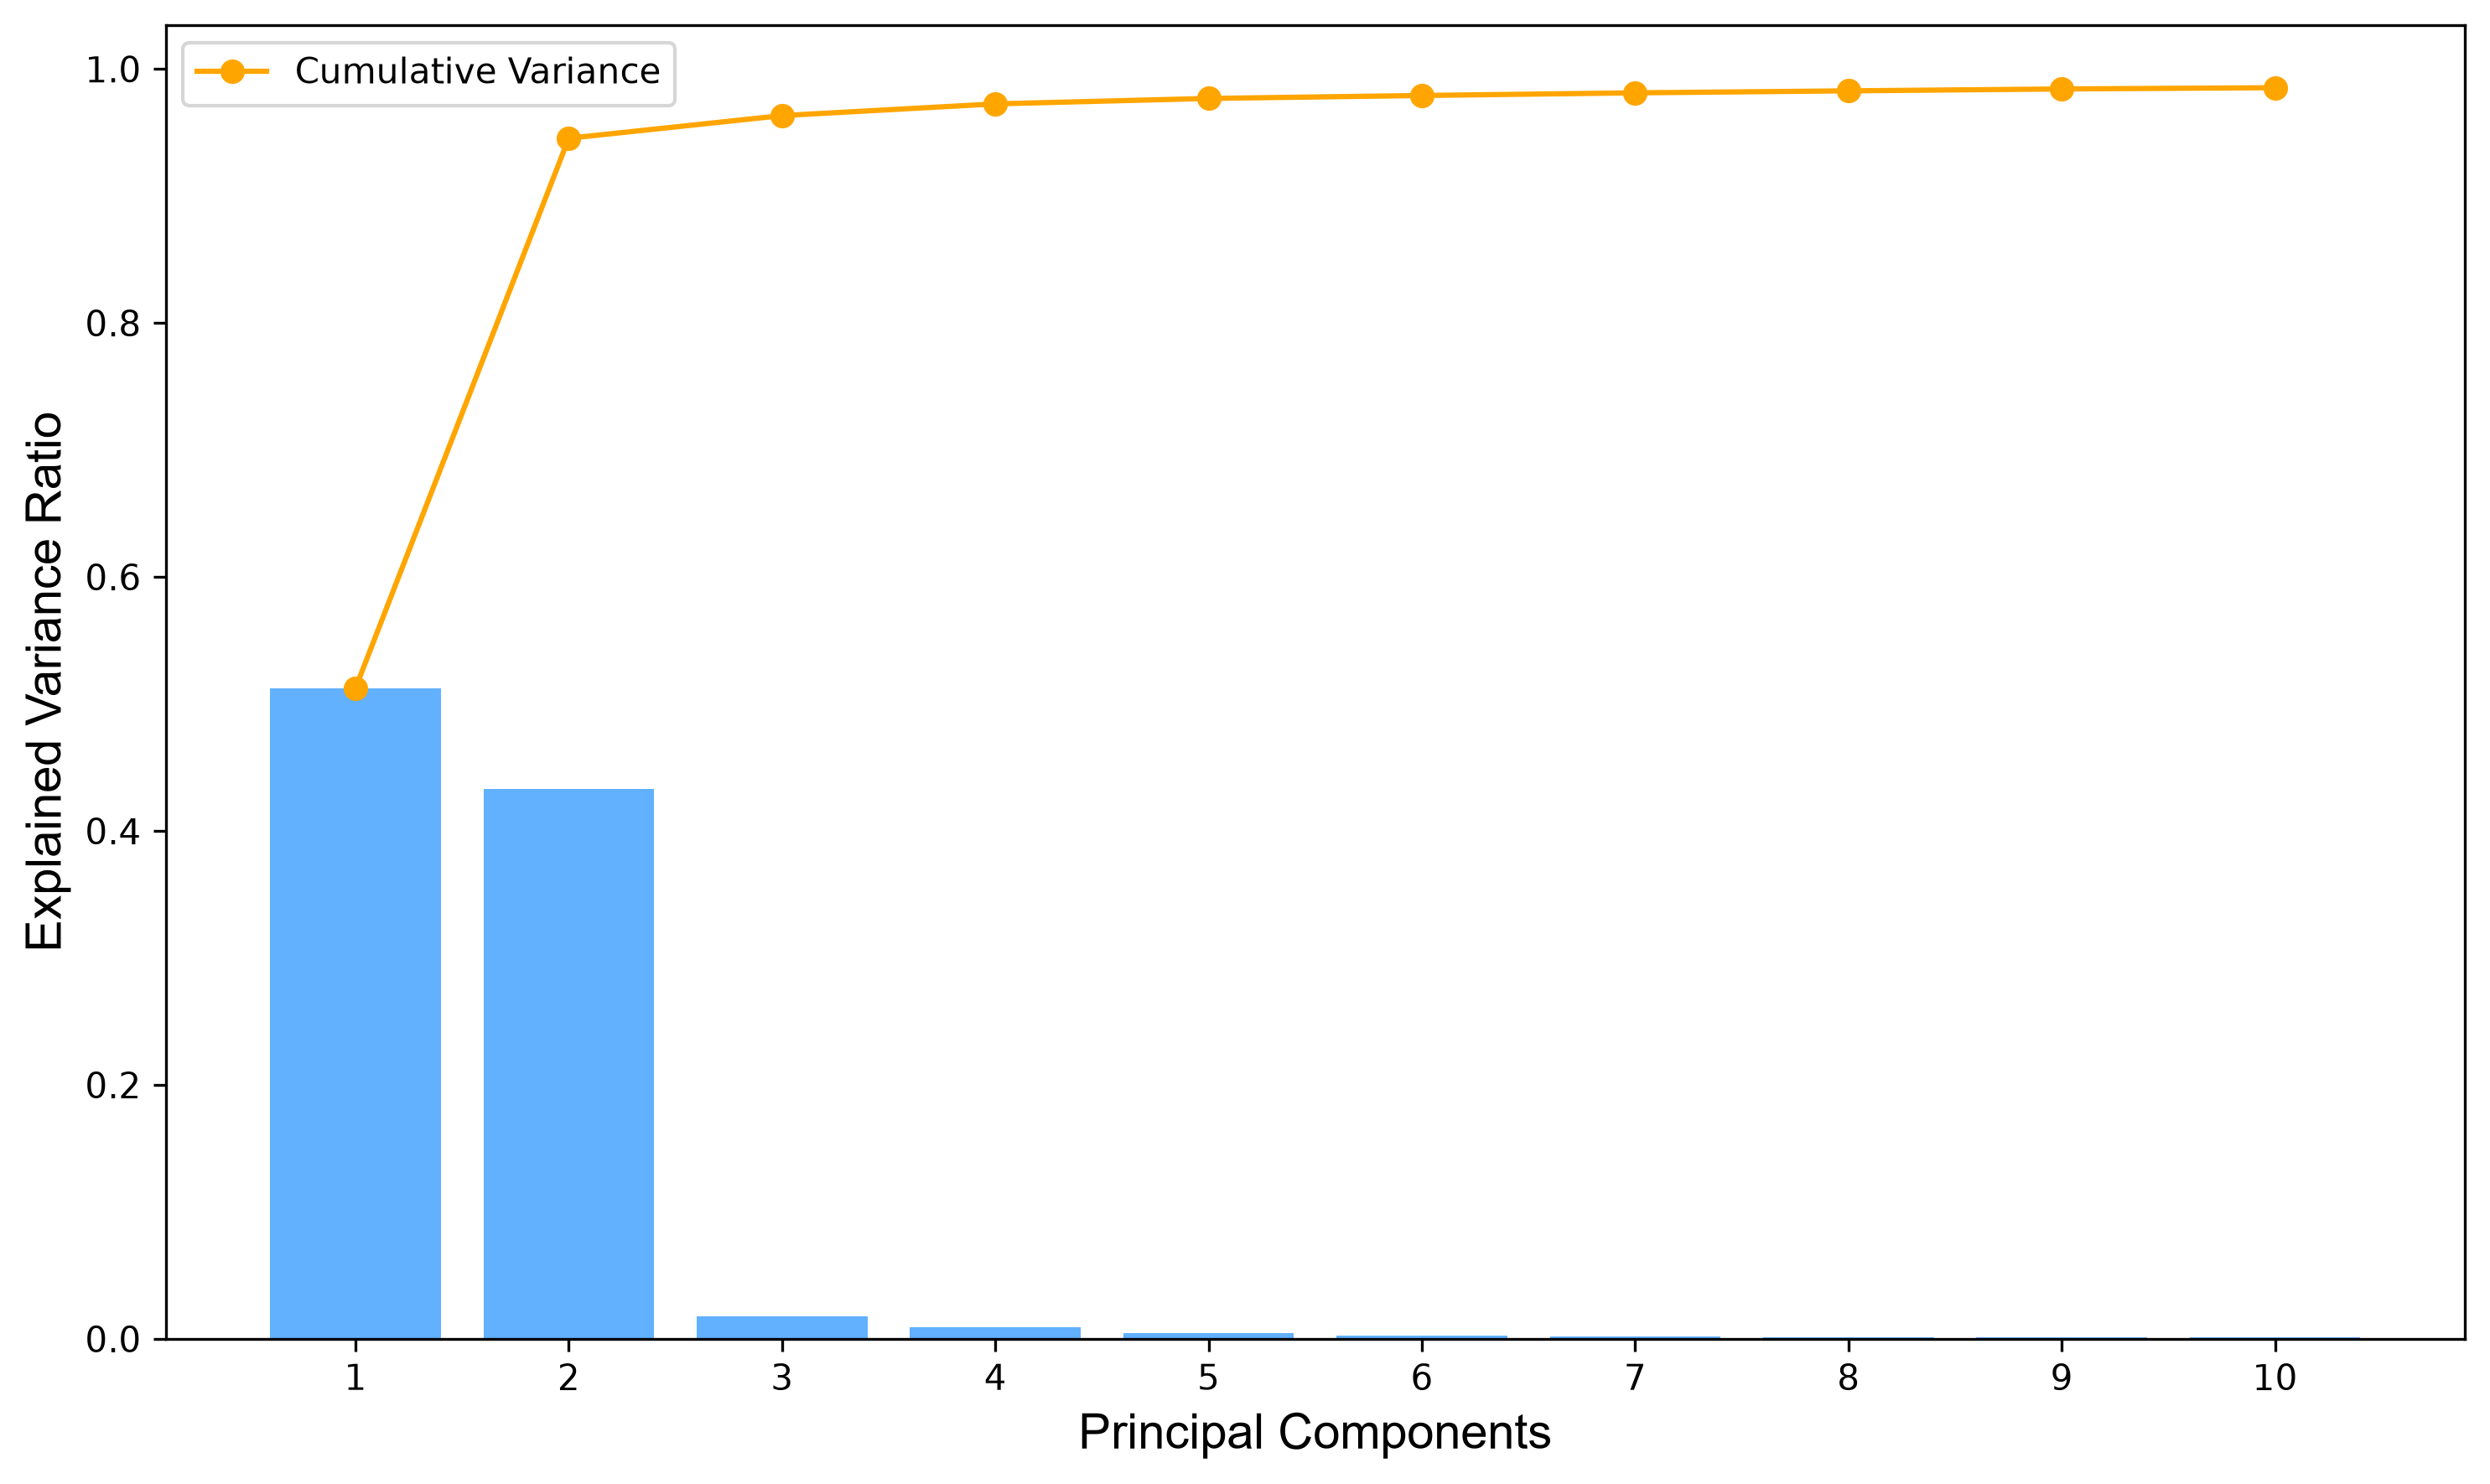

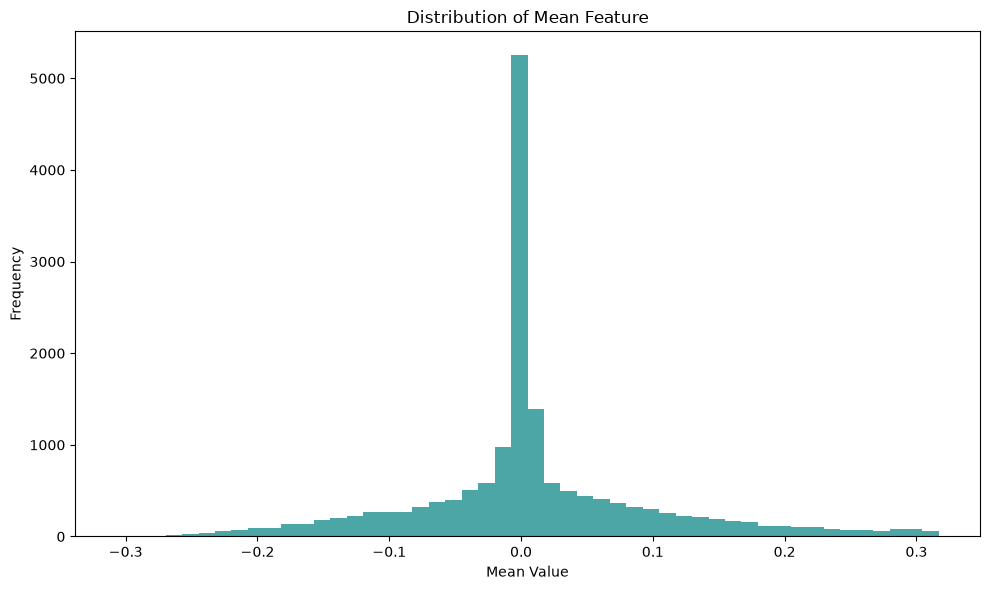

In [23]:
# PCA Variance Plot
plt.figure(figsize=(10, 6), dpi=300)
pca = PCA(n_components=10)
pca_features = pca.fit_transform(scaled_features)
explained_variance = pca.explained_variance_ratio_

# Plot explained variance ratio
plt.bar(range(1, len(explained_variance) + 1), explained_variance, alpha=0.7, color='dodgerblue')
plt.plot(range(1, len(explained_variance) + 1), np.cumsum(explained_variance), marker='o', color='orange', label='Cumulative Variance')
#plt.title('Explained Variance by PCA Components', fontsize=16, fontweight='bold')
plt.xlabel('Principal Components', fontsize=14,fontname='Arial')
plt.ylabel('Explained Variance Ratio', fontsize=14, fontname='Arial')
plt.xticks(range(1, len(explained_variance) + 1))
plt.legend()
plt.tight_layout()
# plt.savefig('expv.png', dpi=400)
plt.show()

# Statistical Features Distribution
# 1️⃣ Replace Infinite Values with NaN
stat_features.replace([np.inf, -np.inf], np.nan, inplace=True)

# 2️⃣ Fill NaN Values (Choose One Option)
stat_features = stat_features.fillna(stat_features.mean())

stat_features['mean'].plot(kind='hist', bins=50, alpha=0.7, color='teal', figsize=(10, 6), title='Distribution of Mean Feature')
plt.xlabel('Mean Value')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [24]:
from sklearn.feature_selection import VarianceThreshold,chi2

# Drop the target variable
features = final_dataset.drop('class', axis=1)

# 1️⃣ Replace Infinite Values with NaN
features.replace([np.inf, -np.inf], np.nan, inplace=True)

# 2️⃣ Fill NaN Values (Choose One Option)
features = features.fillna(features.mean())  # Option 1: Fill with mean
# features = features.dropna()               # Option 2: Drop rows with NaN

# 3️⃣ Apply Variance Threshold for Feature Selection
threshold = 0.9  # Adjust as needed
vr = VarianceThreshold(threshold=threshold)
vr.fit(features)

# Get selected features
selected_features = features.columns[vr.get_support()]

print("Selected Features:", selected_features)
print('\n length:',len(selected_features))

Selected Features: Index(['Column_1', 'Column_2', 'Column_3', 'Column_4', 'Column_5', 'Column_6',
       'Column_7', 'Column_8', 'Column_9', 'Column_10',
       ...
       'fft_max', 'fft_energy', 'fundamental_amp', 'wavelet_coef_0',
       'impulse_factor', 'shape_factor', 'PC1', 'PC2', 'PC3', 'PC4'],
      dtype='str', length=114)

 length: 114


In [25]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
lbl = LabelEncoder()
std = StandardScaler()
y = final_dataset['class']

In [26]:
features.shape, y.shape

((16983, 141), (16983,))

Selected features based on ANOVA F-Scores: ['fundamental_amp', 'std_dev', 'fft_max', 'fft_std_dev', 'rms', 'variance', 'iqr', 'fft_energy', 'energy', 'range', 'min', 'fft_mean', 'thd_global', 'wavelet_coef_4', 'entropy']

ANOVA F-Scores:
              Feature      F_score
121  fundamental_amp  3367.337543
101          std_dev  3335.581990
115          fft_max  3262.773771
114      fft_std_dev  3075.993448
110              rms  3027.191419
111         variance  3001.232380
107              iqr  2959.832604
116       fft_energy  2865.742909
109           energy  2865.742909
108            range  2610.286771
102              min  1649.400256
113         fft_mean  1435.200102
120       thd_global  1235.141652
126   wavelet_coef_4  1156.371282
112          entropy  1096.907360


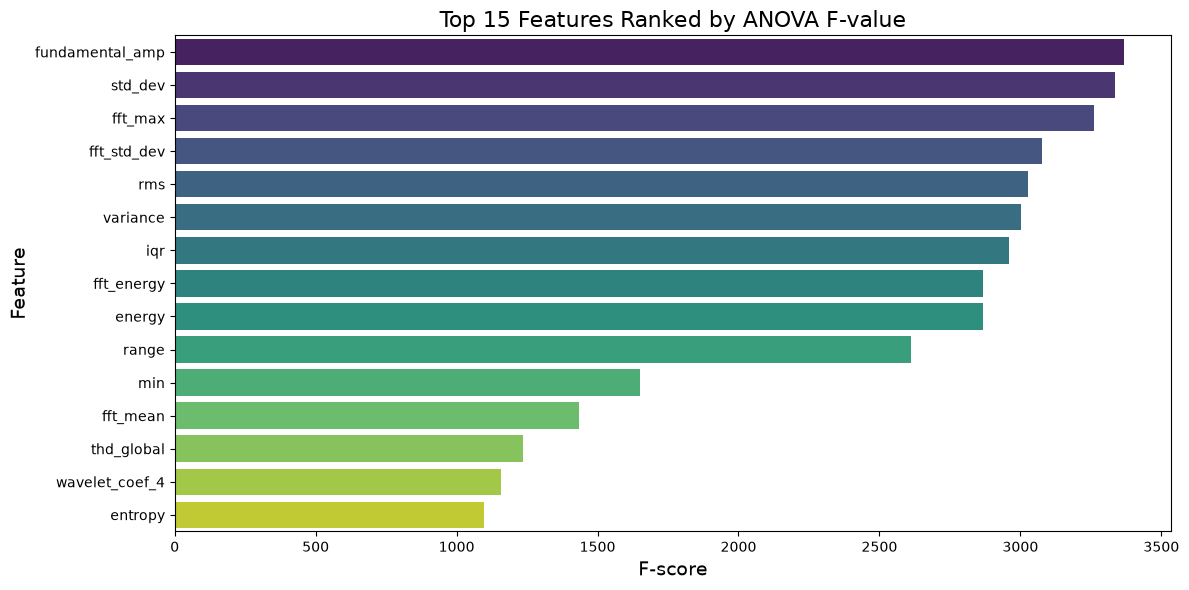

In [27]:
# 1️⃣ Replace Infinite Values with NaN
features.replace([np.inf, -np.inf], np.nan, inplace=True)

# 2️⃣ Fill NaN Values (Choose One Option)
features = features.fillna(features.mean()) 

from sklearn.feature_selection import f_classif

# Compute ANOVA F-values
f_values, p_values = f_classif(features, y)

# Create DataFrame of results
anova_results = pd.DataFrame({'Feature': features.columns, 'F_score': f_values})
anova_results = anova_results.sort_values(by='F_score', ascending=False)

# Print the selected features
selected_features = anova_results['Feature'].head(15).tolist()
print("Selected features based on ANOVA F-Scores:", selected_features)
print("\nANOVA F-Scores:\n", anova_results.head(15))

# Step 4: Sort features by F-score (descending)
feature_scores = anova_results.sort_values(by='F_score', ascending=False).head(15)

# Step 5: Plot
plt.figure(figsize=(12, 6))
sns.barplot(x='F_score', y='Feature', data=feature_scores, palette='viridis')
plt.title('Top 15 Features Ranked by ANOVA F-value', fontsize=16)
plt.xlabel('F-score', fontsize=14)
plt.ylabel('Feature', fontsize=14)
plt.tight_layout()
plt.show()

Selected features based on correlation threshold 0.8:
['fundamental_amp', 'std_dev', 'fft_max', 'fft_std_dev', 'rms', 'variance', 'iqr', 'fft_energy', 'energy', 'range', 'min', 'fft_mean', 'thd_global', 'wavelet_coef_4', 'entropy']


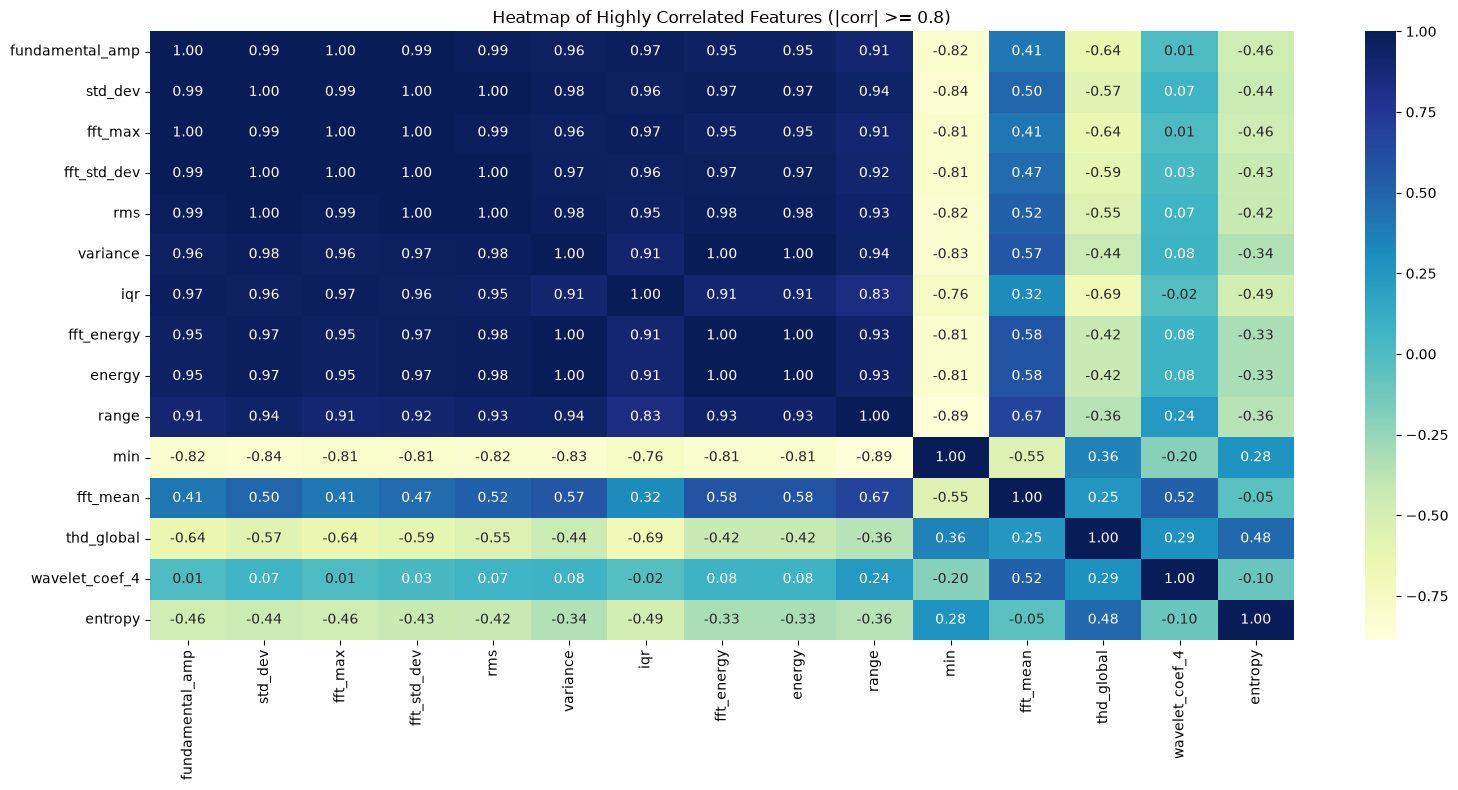

In [28]:
# Compute the correlation matrix
correlation_matrix = final_dataset[list(selected_features)].corr()

# Define a threshold for correlation
threshold = 0.8

# Identify highly correlated features
high_corr_pairs = correlation_matrix[(correlation_matrix.abs() >= threshold) & (correlation_matrix.abs() < 1)]
selected_features_ = high_corr_pairs.columns[high_corr_pairs.any()].tolist()

#selected_features.extend(['Label', 'Attack Type', 'Attack Tool'])

# Create a new DataFrame with only selected features
filtered_df = final_dataset[selected_features_]

# Display the selected features
print(f"Selected features based on correlation threshold {threshold}:\n{selected_features}")

# Plot the filtered heatmap
plt.figure(figsize=(16, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='YlGnBu', fmt=".2f")
plt.title(f"Heatmap of Highly Correlated Features (|corr| >= {threshold})")
plt.tight_layout()
# plt.savefig('heatmap.png')
plt.show()

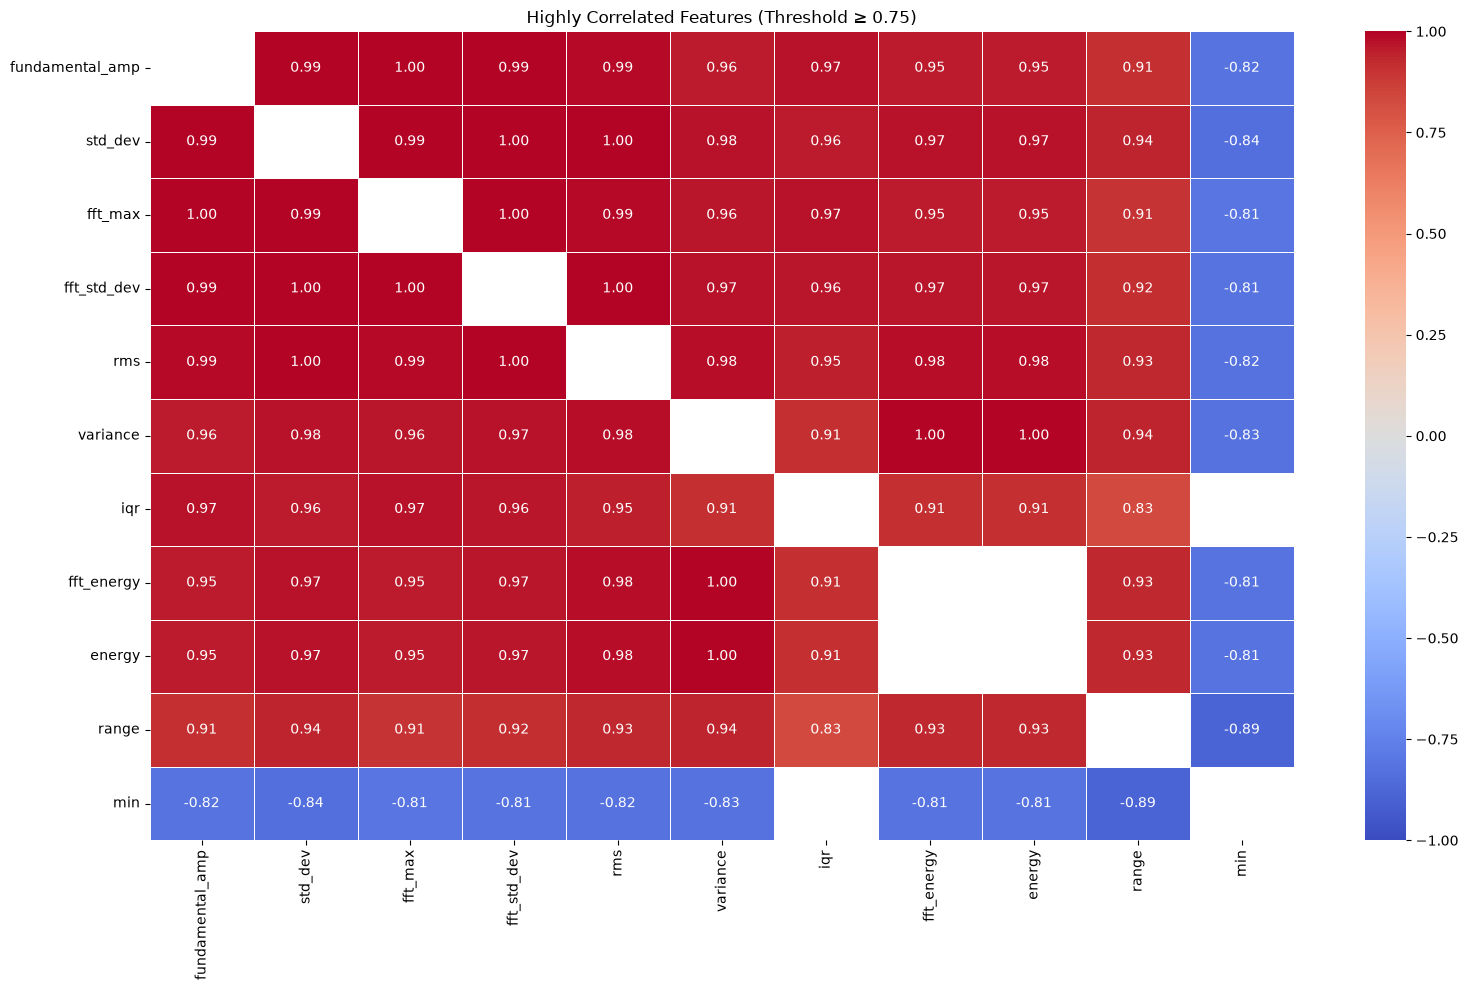

In [29]:
# Compute correlation matrix for selected high-variance features
correlation_matrix = final_dataset[selected_features].corr()

# Define threshold for high correlation (e.g., |0.75| or above)
threshold = 0.8

# Filter only highly correlated features
high_corr_features = correlation_matrix[(correlation_matrix.abs() >= threshold) & (correlation_matrix.abs() < 1.0)]

# Drop rows and columns that are entirely NaN (i.e., no strong correlation)
high_corr_features = high_corr_features.dropna(how='all', axis=0).dropna(how='all', axis=1)

# Plot heatmap only if there are highly correlated features
if not high_corr_features.empty:
    plt.figure(figsize=(16, 10))
    sns.heatmap(high_corr_features, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
    plt.title('Highly Correlated Features (Threshold ≥ 0.75)')
    plt.tight_layout()
    # plt.savefig('high_correlation_heatmap.png', dpi=300)
    plt.show()
else:
    print("No features with correlation above the threshold.")

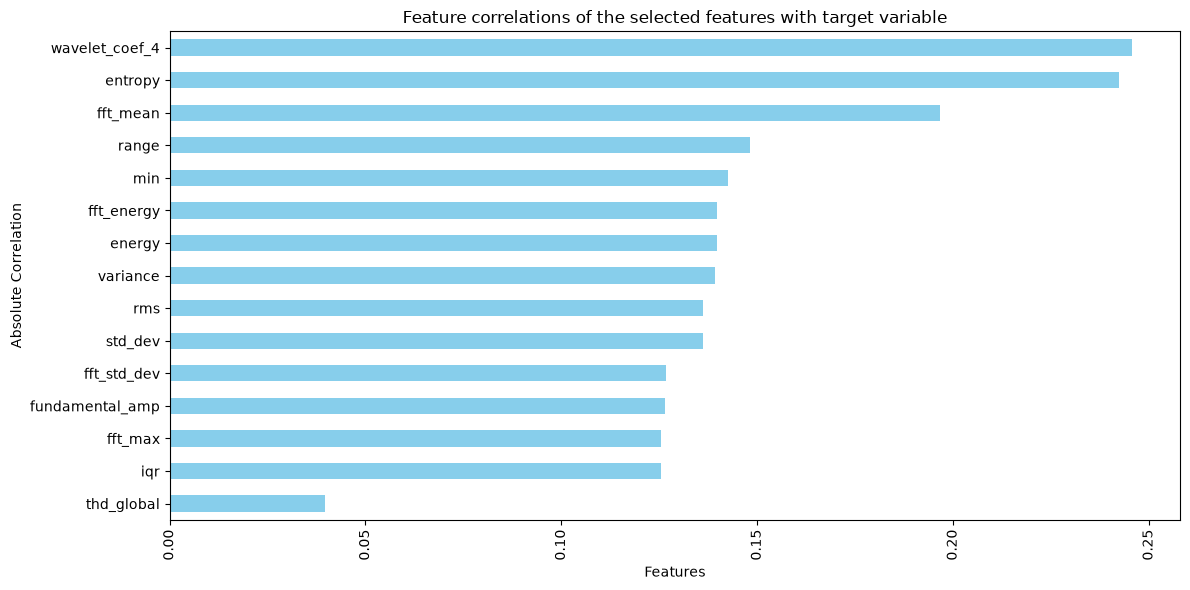

In [30]:
correlations = pd.concat([final_dataset[selected_features],final_dataset['class']],axis=1).corr()['class'].drop('class')
sorted_correlations = correlations.abs().sort_values(ascending=True).head(20)


plt.figure(figsize=(12,6))
sorted_correlations.plot(kind='barh',color='skyblue',title='Feature correlations of the selected features with target variable')
plt.xlabel('Features')
plt.ylabel('Absolute Correlation')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [31]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
lbl = LabelEncoder()
std = StandardScaler()

X = final_dataset.drop(['class','wavelet_coef_0'],axis=1)

# Handle Inf and NaN values before training
X.replace([np.inf, -np.inf], np.nan, inplace=True)  # Convert infinite values to NaN
X.fillna(X.mean(), inplace=True)  # Replace NaN with mean values

# Standardize the data
X_scaled = std.fit_transform(X)

y = final_dataset['class']

In [32]:
from sklearn.model_selection import train_test_split 
X_train, X_test, y_train, y_test = train_test_split(X_scaled,y,random_state=42,test_size=0.2)

In [33]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((13586, 140), (3397, 140), (13586,), (3397,))

Accuracy of RandomForest: 93.1999 %
Recall of RandomForest: 93.1999 %
Precision of RandomForest: 93.2482 %
F1 Score of RandomForest: 93.1503 %
ROC AUC of RandomForest: 99.8043 %
--------------------------------------------------
Accuracy of XGBoost: 95.5255 %
Recall of XGBoost: 95.5255 %
Precision of XGBoost: 95.5569 %
F1 Score of XGBoost: 95.5134 %
ROC AUC of XGBoost: 99.9227 %
--------------------------------------------------
Accuracy of ExtraTrees: 89.1080 %
Recall of ExtraTrees: 89.1080 %
Precision of ExtraTrees: 89.2197 %
F1 Score of ExtraTrees: 89.0635 %
ROC AUC of ExtraTrees: 99.6468 %
--------------------------------------------------
Accuracy of SVM: 80.6005 %
Recall of SVM: 80.6005 %
Precision of SVM: 81.8621 %
F1 Score of SVM: 80.2573 %
ROC AUC of SVM: 99.4765 %
--------------------------------------------------
Accuracy of SVC quadratic kernel: 84.1625 %
Recall of SVC quadratic kernel: 84.1625 %
Precision of SVC quadratic kernel: 84.8417 %
F1 Score of SVC quadratic kernel:

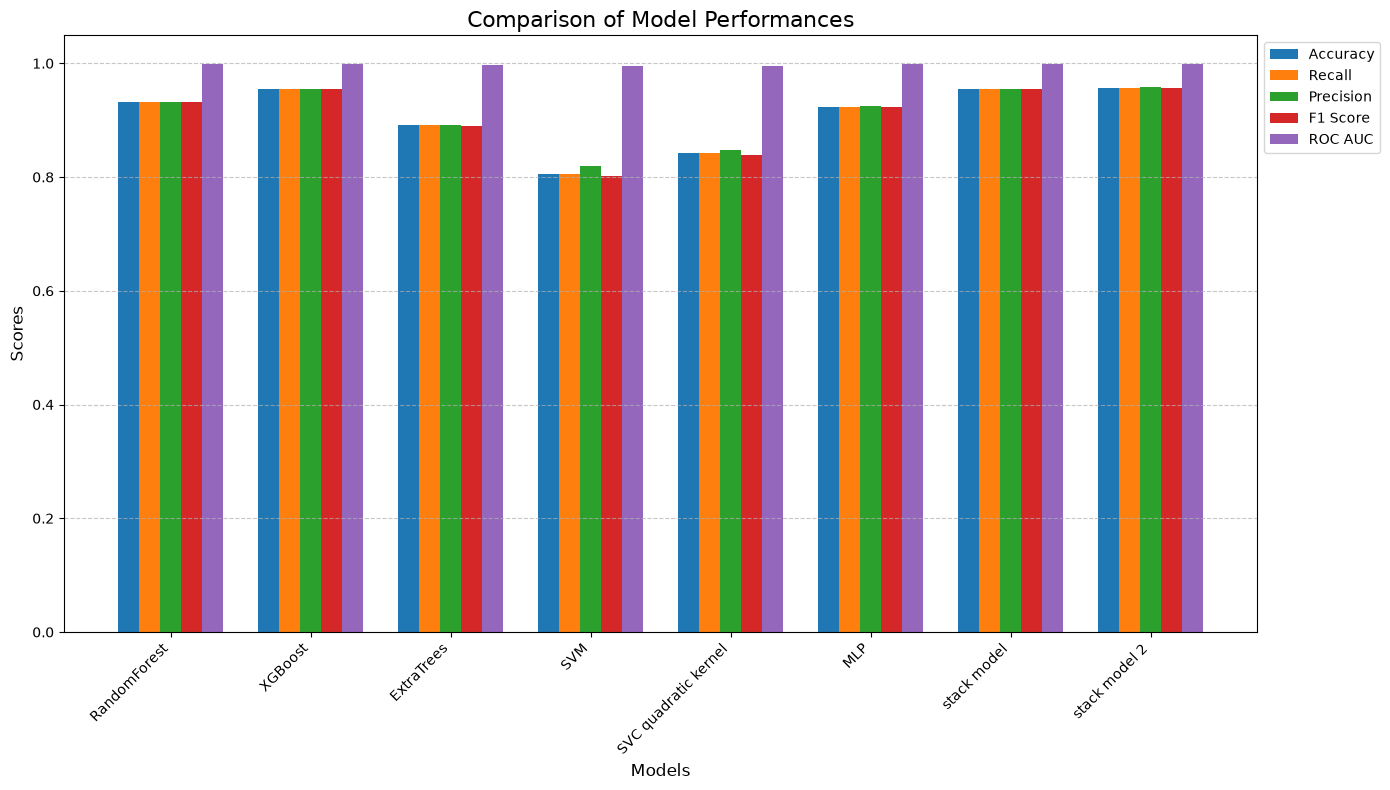


Performance Comparison Table:
                  Model  Accuracy    Recall  Precision  F1 Score   ROC AUC
0          RandomForest  0.931999  0.931999   0.932482  0.931503  0.998043
1               XGBoost  0.955255  0.955255   0.955569  0.955134  0.999227
2            ExtraTrees  0.891080  0.891080   0.892197  0.890635  0.996468
3                   SVM  0.806005  0.806005   0.818621  0.802573  0.994765
4  SVC quadratic kernel  0.841625  0.841625   0.848417  0.838102  0.995231
5                   MLP  0.923756  0.923756   0.924127  0.923604  0.997960
6           stack model  0.954077  0.954077   0.954551  0.954042  0.997985
7         stack model 2  0.957021  0.957021   0.957471  0.957032  0.998221


In [36]:
from sklearn.svm import SVC
from sklearn.ensemble import StackingClassifier
from sklearn.neural_network import MLPClassifier


rf = RandomForestClassifier(random_state = 42, criterion='gini')
xgb = XGBClassifier(random_state=42)
ext = ExtraTreesClassifier(random_state=42)
sv = SVC(kernel='rbf', probability=True)
sv_quad=SVC(kernel='poly',degree=2,coef0=1,C=1.0,probability=True)
mlp = MLPClassifier(hidden_layer_sizes=(100,),max_iter = 500,random_state=42)


# Stacking Classifier (Combining multiple models)
stacking_model = StackingClassifier(
    estimators=[
        ('xgb', xgb),
        ('svm', sv),
    ],
    final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
)
stacking_model2 = StackingClassifier(
    estimators=[
        ('xgb', xgb),
        ('svm', sv_quad),
    ],
    final_estimator=RandomForestClassifier(n_estimators=100, random_state=42)
)


models = {'RandomForest': rf,
          'XGBoost': xgb,
          'ExtraTrees':ext,
          'SVM': sv,
          'SVC quadratic kernel':sv_quad,
          'MLP': mlp,
          'stack model': stacking_model,
          'stack model 2':stacking_model2}


model_names = []
accuracies = []
recalls = []
precisions = []
f1_scores = []
roc_auc_scores = []


# Check if the target variable is multiclass
is_multiclass = len(np.unique(y)) > 2

if is_multiclass:
    # Binarize the output for multiclass classification
    y_test_bin = label_binarize(y_test, classes=np.unique(y))
    n_classes = y_test_bin.shape[1]

# Train models and evaluate performance
for key, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Calculate accuracy, recall, precision, and F1 score
    acc = accuracy_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred, average='weighted')
    precision = precision_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    # Handle ROC AUC calculation for binary vs. multiclass
    if is_multiclass:
        # Predict probabilities for all classes
        y_prob = model.predict_proba(X_test)

        # Compute micro-average ROC AUC
        fpr, tpr, _ = roc_curve(y_test_bin.ravel(), y_prob.ravel())
        roc_auc = auc(fpr, tpr)
    else:
        # For binary classification, compute ROC AUC directly
        y_prob = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        roc_auc = auc(fpr, tpr)

    # Store metrics
    model_names.append(key)
    accuracies.append(acc)
    recalls.append(recall)
    precisions.append(precision)
    f1_scores.append(f1)
    roc_auc_scores.append(roc_auc)

    # Print metrics
    print(f"Accuracy of {key}: {acc * 100:.4f} %")
    print(f"Recall of {key}: {recall * 100:.4f} %")
    print(f"Precision of {key}: {precision * 100:.4f} %")
    print(f"F1 Score of {key}: {f1 * 100:.4f} %")
    print(f"ROC AUC of {key}: {roc_auc * 100:.4f} %")
    print("-" * 50)

# Create a DataFrame for comparison
performance_df = pd.DataFrame({
    "Model": model_names,
    "Accuracy": accuracies,
    "Recall": recalls,
    "Precision": precisions,
    "F1 Score": f1_scores,
    "ROC AUC": roc_auc_scores
})

# Plot comparison chart
metrics = ["Accuracy", "Recall", "Precision", "F1 Score", "ROC AUC"]
x = np.arange(len(model_names))  # X-axis positions for the models
width = 0.15  # Width of the bars

fig, ax = plt.subplots(figsize=(14, 8))
for i, metric in enumerate(metrics):
    ax.bar(x + i * width, performance_df[metric], width, label=metric)

ax.set_xlabel("Models", fontsize=12)
ax.set_ylabel("Scores", fontsize=12)
ax.set_title("Comparison of Model Performances", fontsize=16)
ax.set_xticks(x + width * (len(metrics) - 1) / 2)
ax.set_xticklabels(model_names, rotation=45, ha="right")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

# Display the performance DataFrame
print("\nPerformance Comparison Table:")
print(performance_df)

Accuracy of Voting: 95.7021 %
Recall of Voting: 95.7021 %
Precision of Voting: 95.7516 %
F1 Score of Voting: 95.6986 %
ROC AUC of Voting: 99.9019 %
--------------------------------------------------


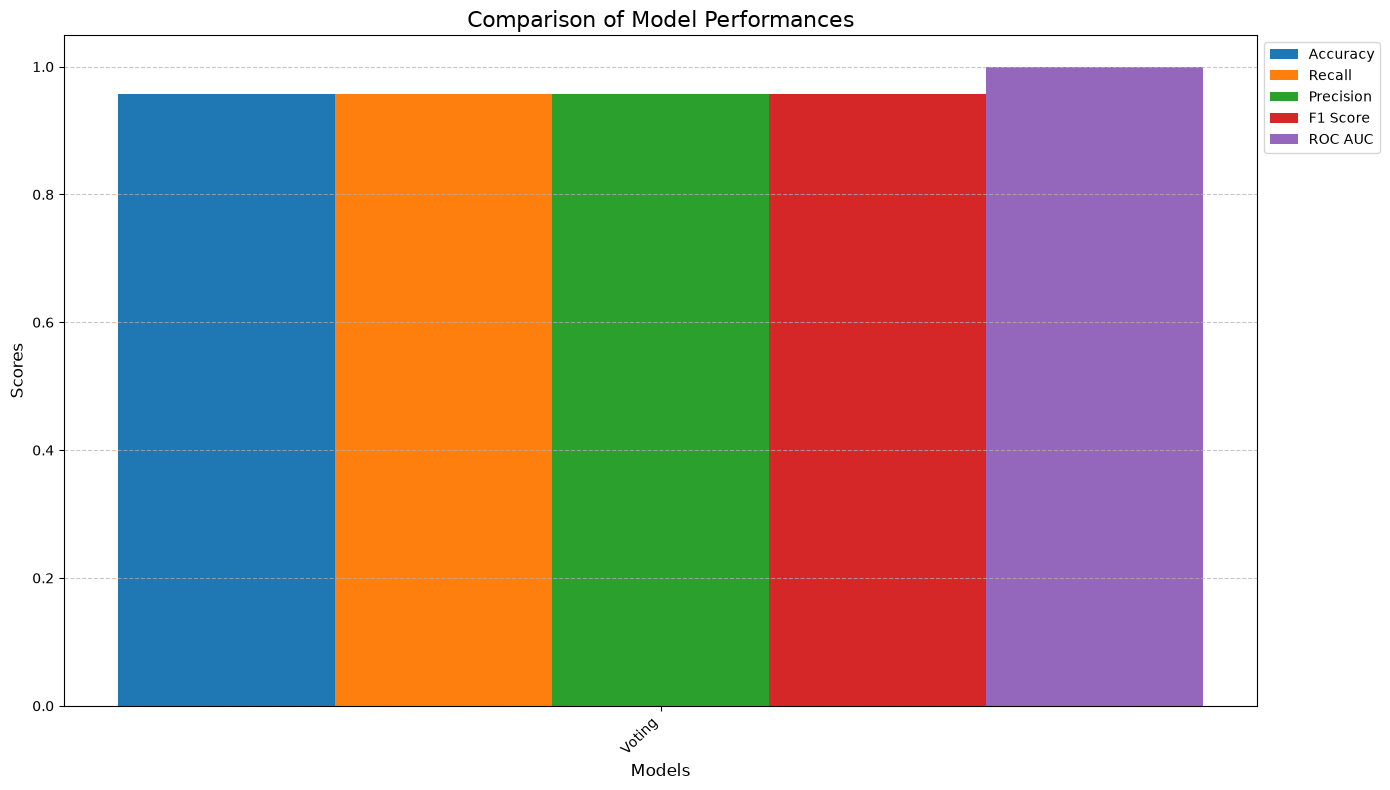


Performance Comparison Table:
    Model  Accuracy    Recall  Precision  F1 Score   ROC AUC
0  Voting  0.957021  0.957021   0.957516  0.956986  0.999019


In [37]:
from sklearn.svm import SVC
from sklearn.ensemble import StackingClassifier,VotingClassifier
from sklearn.neural_network import MLPClassifier



voting_classifier=VotingClassifier(estimators=[('xgb',xgb),('stack2',stacking_model2),('stack',stacking_model)],
                                   voting='soft')

models = {'Voting':voting_classifier}


model_names = []
accuracies = []
recalls = []
precisions = []
f1_scores = []
roc_auc_scores = []


# Check if the target variable is multiclass
is_multiclass = len(np.unique(y)) > 2

if is_multiclass:
    # Binarize the output for multiclass classification
    y_test_bin = label_binarize(y_test, classes=np.unique(y))
    n_classes = y_test_bin.shape[1]

# Train models and evaluate performance
for key, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Calculate accuracy, recall, precision, and F1 score
    acc = accuracy_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred, average='weighted')
    precision = precision_score(y_test, y_pred, average='weighted')
    f1 = f1_score(y_test, y_pred, average='weighted')

    # Handle ROC AUC calculation for binary vs. multiclass
    if is_multiclass:
        # Predict probabilities for all classes
        y_prob = model.predict_proba(X_test)

        # Compute micro-average ROC AUC
        fpr, tpr, _ = roc_curve(y_test_bin.ravel(), y_prob.ravel())
        roc_auc = auc(fpr, tpr)
    else:
        # For binary classification, compute ROC AUC directly
        y_prob = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        roc_auc = auc(fpr, tpr)

    # Store metrics
    model_names.append(key)
    accuracies.append(acc)
    recalls.append(recall)
    precisions.append(precision)
    f1_scores.append(f1)
    roc_auc_scores.append(roc_auc)

    # Print metrics
    print(f"Accuracy of {key}: {acc * 100:.4f} %")
    print(f"Recall of {key}: {recall * 100:.4f} %")
    print(f"Precision of {key}: {precision * 100:.4f} %")
    print(f"F1 Score of {key}: {f1 * 100:.4f} %")
    print(f"ROC AUC of {key}: {roc_auc * 100:.4f} %")
    print("-" * 50)

# Create a DataFrame for comparison
performance_df = pd.DataFrame({
    "Model": model_names,
    "Accuracy": accuracies,
    "Recall": recalls,
    "Precision": precisions,
    "F1 Score": f1_scores,
    "ROC AUC": roc_auc_scores
})

# Plot comparison chart
metrics = ["Accuracy", "Recall", "Precision", "F1 Score", "ROC AUC"]
x = np.arange(len(model_names))  # X-axis positions for the models
width = 0.15  # Width of the bars

fig, ax = plt.subplots(figsize=(14, 8))
for i, metric in enumerate(metrics):
    ax.bar(x + i * width, performance_df[metric], width, label=metric)

ax.set_xlabel("Models", fontsize=12)
ax.set_ylabel("Scores", fontsize=12)
ax.set_title("Comparison of Model Performances", fontsize=16)
ax.set_xticks(x + width * (len(metrics) - 1) / 2)
ax.set_xticklabels(model_names, rotation=45, ha="right")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), fontsize=10)
ax.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

# Display the performance DataFrame
print("\nPerformance Comparison Table:")
print(performance_df)

In [40]:
import numpy as np
import pandas as pd

def calculate_xpqrs_parameters(U):
    """
    Calculates Log Energy, Shannon Energy, and Mobility for a given 1D signal.
    """
    # Add a tiny epsilon to prevent log(0) errors when the waveform crosses zero
    eps = 1e-12
    U_sq = (U ** 2) + eps
    
    # 1. Log Energy (LE)
    le = np.sum(np.log(U_sq))
    
    # 2. Shannon Energy (SE)
    se = -np.sum(U_sq * np.log(U_sq))
    
    # 3. Mobility (Mob)
    # The paper defines Mobility as sqrt( Var(dU/dt) / Var(U) )
    dU = np.diff(U)
    var_dU = np.var(dU)
    var_U = np.var(U) + eps
    mob = np.sqrt(var_dU / var_U)
    
    return [le, se, mob]

def extract_all_xpqrs_features(row):
    """
    Generates the 4 derivatives and extracts the 3 features for all 5 signals.
    """
    # D0 is the original signal
    D0 = row.values if isinstance(row, pd.Series) else row
    
    # Calculate the first 4 approximated derivatives using np.diff
    D1 = np.diff(D0)
    D2 = np.diff(D1)
    D3 = np.diff(D2)
    D4 = np.diff(D3)
    
    features = []
    # Extract LE, SE, and Mob for the original signal and all 4 derivatives
    for signal in [D0, D1, D2, D3, D4]:
        features.extend(calculate_xpqrs_parameters(signal))
        
    return features

# 1. Isolate the 100 signal columns (excluding target labels)
signal_columns = combined_df.iloc[:, :100]

# 2. Apply the extraction across the dataset
print("Extracting XPQRS features...")
xpqrs_features_df = signal_columns.apply(extract_all_xpqrs_features, axis=1, result_type="expand")

# 3. Dynamically assign the 15 column names
col_names = []
for i in range(5):
    prefix = "Orig" if i == 0 else f"D{i}"
    col_names.extend([f"{prefix}_LE", f"{prefix}_SE", f"{prefix}_Mobility"])
    
xpqrs_features_df.columns = col_names

# 4. Merge back with your target labels
final_xpqrs_df = pd.concat([xpqrs_features_df, combined_df['class']], axis=1)

display(final_xpqrs_df.head())

Extracting XPQRS features...


,Orig_LE,Orig_SE,Orig_Mobility,D1_LE,D1_SE,D1_Mobility,D2_LE,D2_SE,D2_Mobility,D3_LE,D3_SE,D3_Mobility,D4_LE,D4_SE,D4_Mobility,class
0,-131.433487,16.690191,0.062245,-677.228746,1.208696,0.063565,-1218.969304,0.009362,0.062228,-1738.259166,0.000053,0.063892,-2240.843128,2.881483e-07,0.061993,Flicker
1,-123.017751,14.113906,0.062348,-674.700805,1.280760,0.063994,-1204.382357,0.010116,0.062556,-1732.274263,0.000058,0.065400,-2224.356012,3.294798e-07,0.062711,Flicker
2,-133.888580,16.380452,0.062563,-677.490717,1.230702,0.063805,-1216.597221,0.009621,0.063801,-1728.257000,0.000058,0.065194,-2230.889256,3.225751e-07,0.066036,Flicker
3,-138.566108,14.516802,0.062854,-671.261117,1.287943,0.063343,-1209.085367,0.009988,0.064138,-1724.848787,0.000060,0.064526,-2224.696966,3.323923e-07,0.065235,Flicker
4,-132.063020,16.521952,0.063582,-672.999584,1.270440,0.061837,-1210.978901,0.009426,0.064696,-1733.338234,0.000058,0.061319,-2238.077513,2.892169e-07,0.065659,Flicker


In [43]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from xgboost import XGBClassifier

# 1. Prepare X (features) and y (target)
# If your label column has a different name (e.g., 'class' or 'Column_101'), update it here
X = final_xpqrs_df.drop(columns=['class'])
y_raw = final_xpqrs_df['class']

# 2. Encode the string labels into integers (0 to 16)
le = LabelEncoder()
y = le.fit_transform(y_raw)

# 3. Train/Test Split (80% training, 20% testing)
# stratify=y ensures equal representation of all 17 classes in both splits
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Initialize the XGBoost Classifier
# objective='multi:softmax' tells the model to output a single winning class per sample
xgb_model = XGBClassifier(
    objective='multi:softmax', 
    num_class=17, 
    eval_metric='mlogloss', 
    random_state=42
)

# 5. Train the model
print("Training XGBoost model on XPQRS features...")
xgb_model.fit(X_train, y_train)

# 6. Generate predictions
y_pred = xgb_model.predict(X_test)

# 7. Calculate metrics
# Because this is a 17-class problem, we must specify an averaging method. 
# 'weighted' calculates metrics for each class independently and averages them based on class support.
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("-" * 35)
print("XPQRS XGBoost Model Performance:")
print(f"Accuracy:  {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1 Score:  {f1 * 100:.2f}%")
print("-" * 35)

Training XGBoost model on XPQRS features...
-----------------------------------
XPQRS XGBoost Model Performance:
Accuracy:  97.20%
Precision: 97.28%
Recall:    97.20%
F1 Score:  97.19%
-----------------------------------


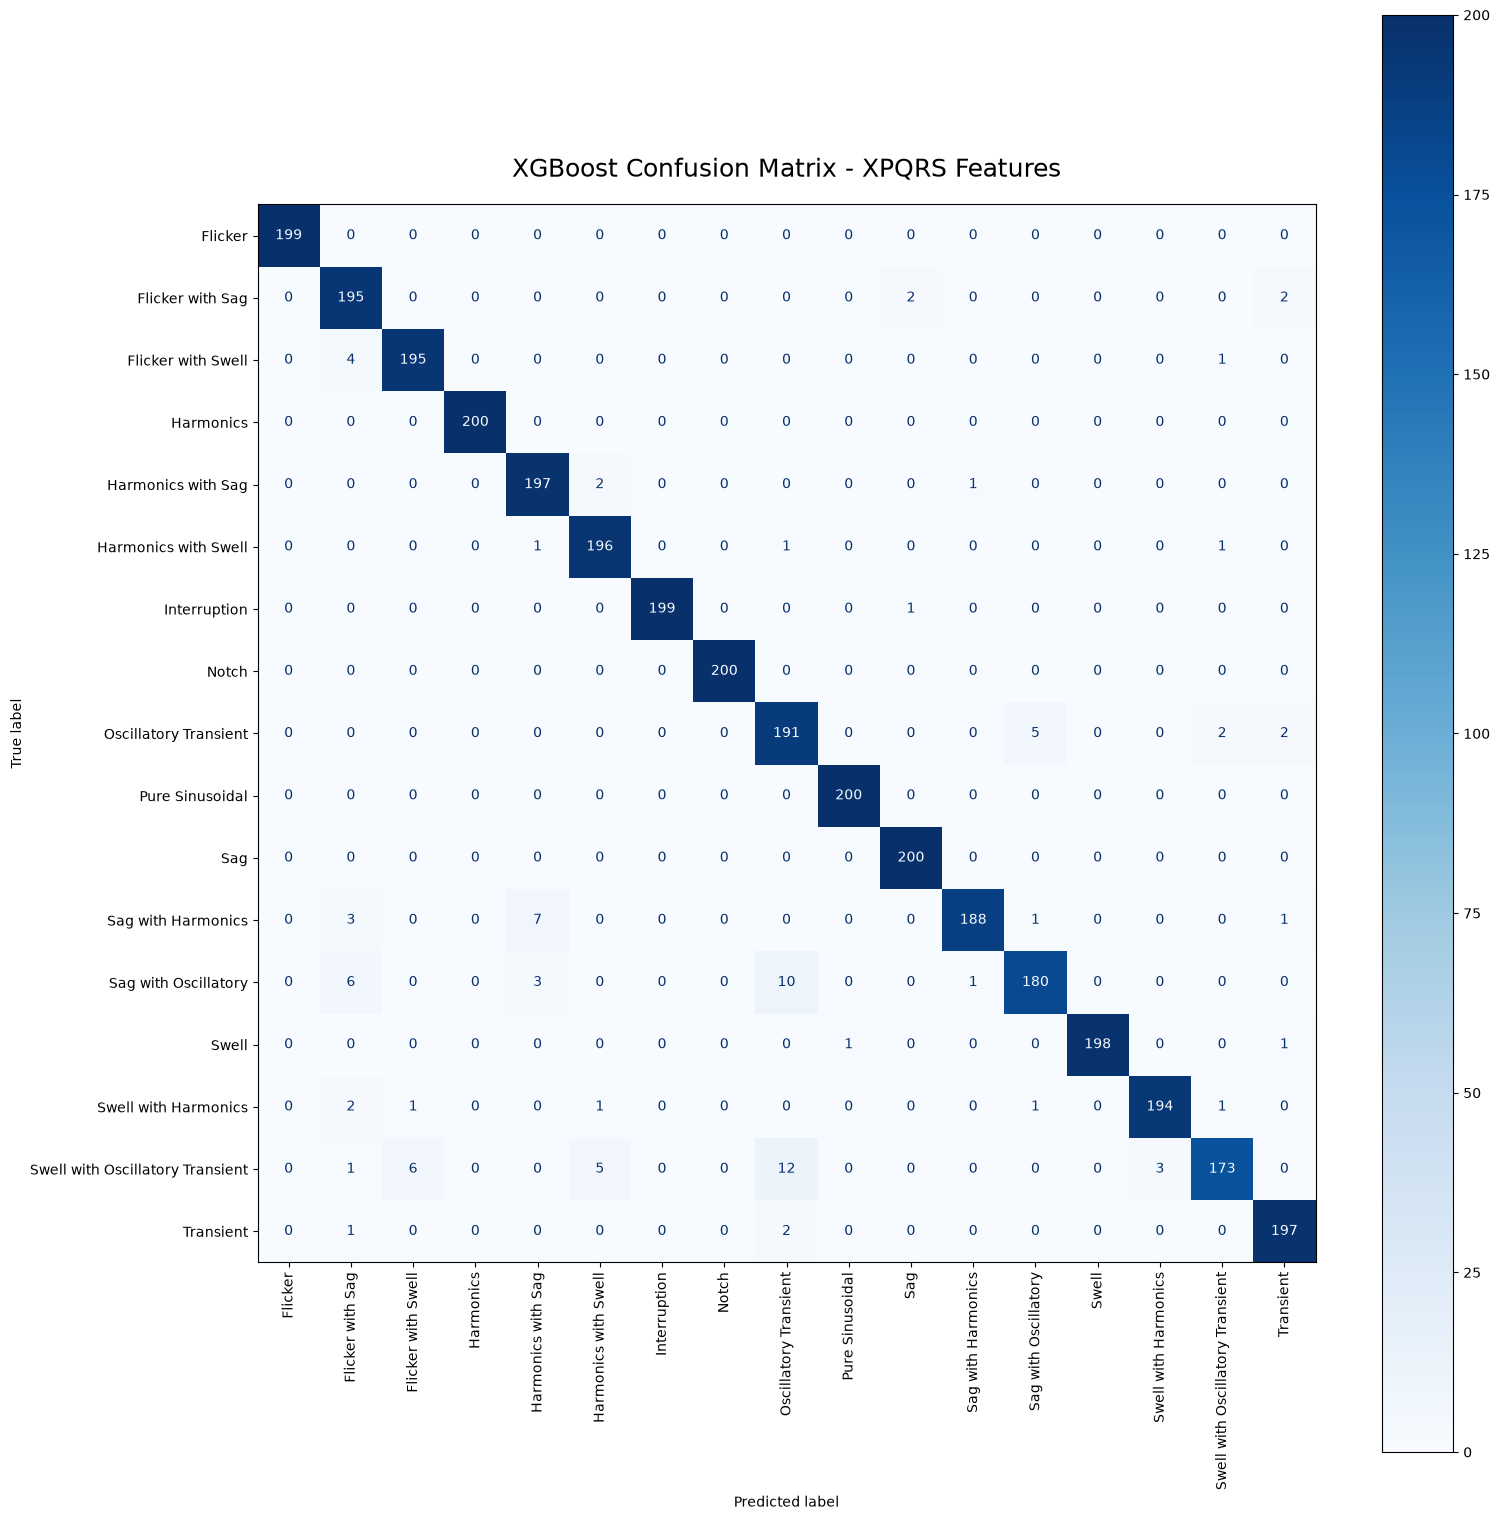

In [44]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# 2. Extract the original string names of your 17 classes from the LabelEncoder
class_names = le.classes_

# 3. Set up the plot with a large figure size to prevent text overlapping
fig, ax = plt.subplots(figsize=(16, 16))

# 4. Create the display object
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

# 5. Plot the matrix
# cmap='Blues' provides a clean gradient. values_format='d' ensures whole numbers.
disp.plot(cmap='Blues', ax=ax, xticks_rotation='vertical', values_format='d')

# 6. Formatting and display
plt.title("XGBoost Confusion Matrix - XPQRS Features", fontsize=18, pad=20)
plt.tight_layout()
plt.show()

In [45]:
import numpy as np
import pandas as pd
import pywt

def extract_envelope_features(row):
    # 1. RMS Voltage: Measures true continuous power, ignoring microsecond spikes
    rms = np.sqrt(np.mean(row**2))
    
    # 2. Wavelet Approximation Energy: Acts as a low-pass filter
    # 'db4' at level 5 strips out high-frequency transients. 
    # Index [0] grabs the Approximation Coefficients (cA5).
    coeffs = pywt.wavedec(row, 'db4', level=5)
    approx_coeffs = coeffs[0] 
    energy_approx = np.sum(approx_coeffs**2)
    
    return pd.Series([rms, energy_approx])

# Extract the new features from your original 100-point signals
print("Extracting RMS and Wavelet Approximation features...")
envelope_features_df = signal_columns.apply(extract_envelope_features, axis=1)
envelope_features_df.columns = ['RMS_Voltage', 'Energy_Approx']

# Combine the new envelope features with your existing XPQRS features
X_enhanced = pd.concat([final_xpqrs_df.drop(columns=['class']), envelope_features_df], axis=1)
final_enhanced_df = pd.concat([final_xpqrs_df['class'], X_enhanced], axis=1)

display(final_enhanced_df.head())

Extracting RMS and Wavelet Approximation features...


,class,Orig_LE,Orig_SE,Orig_Mobility,D1_LE,D1_SE,D1_Mobility,D2_LE,D2_SE,D2_Mobility,D3_LE,D3_SE,D3_Mobility,D4_LE,D4_SE,D4_Mobility,RMS_Voltage,Energy_Approx
0,Flicker,-131.433487,16.690191,0.062245,-677.228746,1.208696,0.063565,-1218.969304,0.009362,0.062228,-1738.259166,0.000053,0.063892,-2240.843128,2.881483e-07,0.061993,0.732584,101.368468
1,Flicker,-123.017751,14.113906,0.062348,-674.700805,1.280760,0.063994,-1204.382357,0.010116,0.062556,-1732.274263,0.000058,0.065400,-2224.356012,3.294798e-07,0.062711,0.757548,52.819738
2,Flicker,-133.888580,16.380452,0.062563,-677.490717,1.230702,0.063805,-1216.597221,0.009621,0.063801,-1728.257000,0.000058,0.065194,-2230.889256,3.225751e-07,0.066036,0.736828,57.466001
3,Flicker,-138.566108,14.516802,0.062854,-671.261117,1.287943,0.063343,-1209.085367,0.009988,0.064138,-1724.848787,0.000060,0.064526,-2224.696966,3.323923e-07,0.065235,0.754087,224.281140
4,Flicker,-132.063020,16.521952,0.063582,-672.999584,1.270440,0.061837,-1210.978901,0.009426,0.064696,-1733.338234,0.000058,0.061319,-2238.077513,2.892169e-07,0.065659,0.739286,245.702386


In [48]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier

# Prepare updated feature set
X = final_enhanced_df.drop(columns=['class'])
y = le.transform(final_enhanced_df['class']) # Using your existing LabelEncoder

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Re-initialize and train
xgb_model_enhanced = XGBClassifier(
    objective='multi:softmax', 
    num_class=17, 
    eval_metric='mlogloss', 
    random_state=42
)
xgb_model_enhanced.fit(X_train, y_train)

# Predict and evaluate
y_pred_enhanced = xgb_model_enhanced.predict(X_test)
new_accuracy = accuracy_score(y_test, y_pred_enhanced)
new_precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
new_recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
new_f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print(f"Enhanced Model Accuracy: {new_accuracy * 100:.2f}%")
print(f"Enhanced Model precisionm: {new_precision * 100:.2f}%")
print(f"Enhanced Model recall: {new_recall * 100:.2f}%")
print(f"Enhanced Model f1: {new_f1 * 100:.2f}%")

Enhanced Model Accuracy: 97.41%
Enhanced Model precisionm: 97.28%
Enhanced Model recall: 97.20%
Enhanced Model f1: 97.19%


In [49]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score

# 1. Define the hyperparameter search space
param_dist = {
    'max_depth': randint(3, 10),              # Tree depth: shallow prevents overfitting, deep captures complex interactions
    'learning_rate': uniform(0.01, 0.2),      # Step size shrinkage
    'n_estimators': randint(100, 400),        # Number of boosting rounds
    'subsample': uniform(0.7, 0.3),           # Fraction of samples used per tree (0.7 to 1.0)
    'colsample_bytree': uniform(0.7, 0.3)     # Fraction of features used per tree (0.7 to 1.0)
}

# 2. Initialize a baseline XGBoost model
xgb_base = XGBClassifier(
    objective='multi:softmax',
    num_class=17,
    eval_metric='mlogloss',
    random_state=42
)

# 3. Configure the Randomized Search
# n_iter=25 means it will randomly test 25 different hyperparameter combinations.
# cv=3 applies 3-fold cross-validation to ensure the accuracy is stable.
random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_dist,
    n_iter=25,
    scoring='accuracy',
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1 # Utilizes all available CPU cores on your machine
)

# 4. Execute the search
print("Initiating hyperparameter optimization... (Grab a coffee, this will take a few minutes)")
random_search.fit(X_train, y_train)

# 5. Extract the best model and evaluate on the test set
best_xgb = random_search.best_estimator_
y_pred_optim = best_xgb.predict(X_test)
optim_accuracy = accuracy_score(y_test, y_pred_optim)

print("-" * 35)
print(f"Optimized Accuracy: {optim_accuracy * 100:.2f}%")
print(f"Best Parameters: {random_search.best_params_}")
print("-" * 35)

Initiating hyperparameter optimization... (Grab a coffee, this will take a few minutes)
Fitting 3 folds for each of 25 candidates, totalling 75 fits
-----------------------------------
Optimized Accuracy: 97.29%
Best Parameters: {'colsample_bytree': np.float64(0.9312901539863683), 'learning_rate': np.float64(0.10875911927287815), 'max_depth': 3, 'n_estimators': 306, 'subsample': np.float64(0.8282623055075649)}
-----------------------------------
